# Klasifikasi Multi-Label ECG 12-Lead dengan NC-GAT

**Mata Kuliah:** Deep Learning

**Pipeline:** Dataset - EDA - Preprocessing - Clean Dataset - Feature Engineering - Model Development - Model Evaluation - Kesimpulan

## Ringkasan

Klasifikasi multi-label ECG 12-lead ke 6 kelas: NSR, SB, STach, AF, IAVB, LBBB.

Model utama: **NC-GAT** (Graph Attention antar-lead + Noise-Consistency Regularization).

Baseline: CNN 1D, Transformer, GAT.

Dataset: PTB-XL (training, validation, test internal) dan Chapman-Shaoxing (test eksternal cross-dataset).

Eksperimen: A (baseline), B (robustness), C (efek noise-consistency), D (cross-dataset), E (XAI stability).


---
## Setup

Import library, set seed, dan siapkan folder output.


In [4]:
!pip install -q wfdb

import os, ast, json, math, random, warnings, platform
import numpy as np
import pandas as pd
import scipy.signal as sps
from scipy.signal import butter, filtfilt
from scipy.stats import spearmanr, binomtest
from scipy.spatial.distance import jensenshannon
from sklearn.metrics import (f1_score, precision_score, recall_score, accuracy_score,
                              roc_auc_score, roc_curve, average_precision_score,
                              multilabel_confusion_matrix, ConfusionMatrixDisplay,
                              classification_report)
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics.pairwise import cosine_similarity
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import wfdb
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
print("PyTorch:", torch.__version__)
print("Python:", platform.python_version())

WORK_DIR = "/kaggle/working/nc_gat_final"
CHECKPOINT_DIR = os.path.join(WORK_DIR, "checkpoints")
RESULTS_DIR = os.path.join(WORK_DIR, "results")
os.makedirs(CHECKPOINT_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)
print("Output dirs OK")


Device: cuda
PyTorch: 2.10.0+cu128
Python: 3.12.13
Output dirs OK


---
## Konfigurasi

Path dataset, parameter sinyal, dan mapping label SCP-ECG (PTB-XL) ke SNOMED-CT.

| SCP (PTB-XL) | SNOMED-CT | Kelas |
|---|---|---|
| SR, SARRH | 426783006 | NSR |
| SBRAD | 426177001 | SB |
| STACH | 427084000 | STach |
| AFIB | 164889003 | AF |
| 1AVB | 270492004 | IAVB |
| CLBBB | 164909002 | LBBB |

Mapping divalidasi terhadap `dx_mapping_scored.csv` dari PhysioNet Challenge 2021. Lima dari enam kelas cocok persis dengan referensi. Kelas NSR selisih sekitar 3 persen karena beberapa kode SCP varian tidak dipetakan eksplisit, dicatat sebagai limitasi.


In [5]:
PTBXL_ROOT = "/kaggle/input/datasets/khyeh0719/ptb-xl-dataset/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.1"
CHAPMAN_ROOT = "/kaggle/input/datasets/erarayamorenzomuten/chapmanshaoxing-12lead-ecg-database/WFDB_ChapmanShaoxing"
DX_MAPPING_URL = "https://raw.githubusercontent.com/physionetchallenges/evaluation-2021/main/dx_mapping_scored.csv"
DX_MAPPING_PATH = "/kaggle/working/dx_mapping_scored.csv"

TARGET_FS = 500
TARGET_SECONDS = 10
TARGET_LENGTH = TARGET_FS * TARGET_SECONDS
LEAD_NAMES = ["I", "II", "III", "aVR", "aVL", "aVF", "V1", "V2", "V3", "V4", "V5", "V6"]
N_LEADS = len(LEAD_NAMES)

FILTER_LOWCUT = 0.5; FILTER_HIGHCUT = 45.0; FILTER_ORDER = 3

SCP_TO_SNOMED = {"SR": 426783006, "SARRH": 426783006, "SBRAD": 426177001,
                 "STACH": 427084000, "AFIB": 164889003, "1AVB": 270492004, "CLBBB": 164909002}
CLASS_CODES = sorted(set(SCP_TO_SNOMED.values()))
CLASS_NAMES = {426783006: "NSR", 426177001: "SB", 427084000: "STach",
               164889003: "AF", 270492004: "IAVB", 164909002: "LBBB"}
NUM_CLASSES = len(CLASS_CODES)
CLASS_NAMES_ORDERED = [CLASS_NAMES[c] for c in CLASS_CODES]

# Parameter training — sama dengan v2, sedikit tuned
BATCH_SIZE = 64
LR = 1e-3
EPOCHS = 25
PATIENCE = 7         # naik dari 6
WARMUP_EPOCHS = 5    # naik dari 3
DROPOUT = 0.25       # turun dari 0.3
WEIGHT_DECAY = 5e-5  # turun dari 1e-4

print("Kelas:", CLASS_NAMES_ORDERED)
print(f"Batch={BATCH_SIZE}, LR={LR}, Epochs={EPOCHS}, Patience={PATIENCE}")
print(f"Dropout={DROPOUT}, WeightDecay={WEIGHT_DECAY}, WarmupEpochs={WARMUP_EPOCHS}")


Kelas: ['AF', 'LBBB', 'IAVB', 'SB', 'NSR', 'STach']
Batch=64, LR=0.001, Epochs=25, Patience=7
Dropout=0.25, WeightDecay=5e-05, WarmupEpochs=5


---
# TAHAP 1: DATASET

Baca PTB-XL dan Chapman-Shaoxing, harmonisasi label ke SNOMED-CT, validasi terhadap referensi PhysioNet.


In [6]:
def download_dx_mapping():
    if not os.path.exists(DX_MAPPING_PATH):
        os.system(f"wget -q {DX_MAPPING_URL} -O {DX_MAPPING_PATH}")
    if not os.path.exists(DX_MAPPING_PATH):
        raise FileNotFoundError("Gagal unduh dx_mapping_scored.csv")
    return pd.read_csv(DX_MAPPING_PATH)


def map_scp_to_snomed(scp_codes_str):
    d = ast.literal_eval(scp_codes_str)
    return sorted({SCP_TO_SNOMED[k] for k in d.keys() if k in SCP_TO_SNOMED})


def multi_hot(codes):
    v = np.zeros(NUM_CLASSES, dtype=np.float32)
    for c in codes:
        if c in CLASS_CODES: v[CLASS_CODES.index(c)] = 1.0
    return v


def build_ptbxl_metadata():
    df = pd.read_csv(os.path.join(PTBXL_ROOT, "ptbxl_database.csv"))
    df["snomed_codes"] = df["scp_codes"].apply(map_scp_to_snomed)
    df["label_vec"] = df["snomed_codes"].apply(multi_hot)
    df = df[df["snomed_codes"].apply(len) > 0].reset_index(drop=True)
    df["record_path"] = df["filename_hr"].apply(lambda p: os.path.join(PTBXL_ROOT, p))
    df["source"] = "ptbxl"
    return df[["patient_id","record_path","source","snomed_codes","label_vec"]]


def parse_chapman_header(hea_path):
    with open(hea_path, "r") as f:
        for line in f:
            if line.strip().startswith("#Dx"):
                raw = line.strip().replace("#Dx:", "")
                return [int(c.strip()) for c in raw.split(",") if c.strip().isdigit()]
    return []


def build_chapman_metadata():
    recs = []
    for fname in [f for f in os.listdir(CHAPMAN_ROOT) if f.endswith(".hea")]:
        dx = parse_chapman_header(os.path.join(CHAPMAN_ROOT, fname))
        rel = sorted(set(dx) & set(CLASS_CODES))
        if not rel: continue
        recs.append({"record_path": os.path.join(CHAPMAN_ROOT, fname.replace(".hea", "")),
                     "source": "chapman", "snomed_codes": rel, "label_vec": multi_hot(rel)})
    return pd.DataFrame(recs)


df_mapping = download_dx_mapping()
df_ptbxl = build_ptbxl_metadata()
df_chapman = build_chapman_metadata()

print(f"PTB-XL  : {len(df_ptbxl)} rekaman | {df_ptbxl['patient_id'].nunique()} pasien")
print(f"Chapman : {len(df_chapman)} rekaman")


PTB-XL  : 20635 rekaman | 17998 pasien
Chapman : 9119 rekaman


In [7]:
def validate_mapping(df, source_column, dataset_name):
    lm = np.stack(df["label_vec"].values)
    counts = lm.sum(axis=0)
    print(f"Validasi distribusi kelas {dataset_name}:")
    for code_val, count in zip(CLASS_CODES, counts):
        ref_row = df_mapping[df_mapping["SNOMEDCTCode"] == code_val]
        ref = int(ref_row[source_column].values[0]) if len(ref_row) else None
        status = "OK" if ref is not None and int(count) == ref else "periksa"
        print(f"  {CLASS_NAMES[code_val]:6s}  hasil={int(count):6d}  referensi={ref}  ({status})")


validate_mapping(df_ptbxl, "PTB_XL", "PTB-XL")
print()
validate_mapping(df_chapman, "Chapman_Shaoxing", "Chapman-Shaoxing")


Validasi distribusi kelas PTB-XL:
  AF      hasil=  1514  referensi=1514  (OK)
  LBBB    hasil=   536  referensi=536  (OK)
  IAVB    hasil=   797  referensi=797  (OK)
  SB      hasil=   637  referensi=637  (OK)
  NSR     hasil= 17552  referensi=18092  (periksa)
  STach   hasil=   826  referensi=826  (OK)

Validasi distribusi kelas Chapman-Shaoxing:
  AF      hasil=  1780  referensi=1780  (OK)
  LBBB    hasil=   205  referensi=205  (OK)
  IAVB    hasil=   247  referensi=247  (OK)
  SB      hasil=  3889  referensi=3889  (OK)
  NSR     hasil=  1826  referensi=1826  (OK)
  STach   hasil=  1568  referensi=1568  (OK)


---
# TAHAP 2: EXPLORATORY DATA ANALYSIS

Statistik dataset, distribusi kelas, contoh sinyal, dan cek kualitas data.


In [8]:
print("=== Statistik Dasar PTB-XL ===")
print(f"Total rekaman     : {len(df_ptbxl)}")
print(f"Pasien unik       : {df_ptbxl['patient_id'].nunique()}")
print(f"Rekaman berulang  : {len(df_ptbxl) - df_ptbxl['patient_id'].nunique()}")

rec_per_patient = df_ptbxl.groupby("patient_id").size()
print("Distribusi jumlah rekaman per pasien:")
print(rec_per_patient.value_counts().sort_index().head(10))


=== Statistik Dasar PTB-XL ===
Total rekaman     : 20635
Pasien unik       : 17998
Rekaman berulang  : 2637
Distribusi jumlah rekaman per pasien:
1    16064
2     1478
3      307
4       90
5       37
6       12
7        5
8        3
9        2
Name: count, dtype: int64


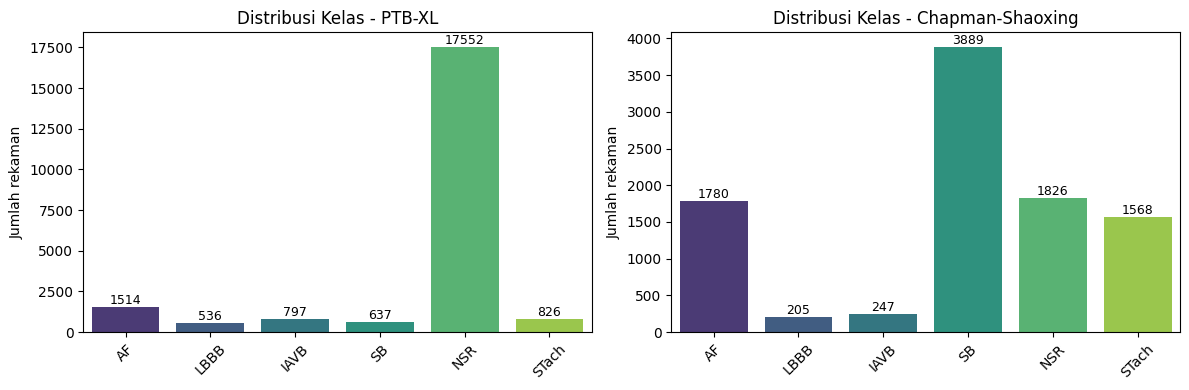

In [9]:
def plot_class_distribution(df_dict):
    fig, axes = plt.subplots(1, len(df_dict), figsize=(6 * len(df_dict), 4))
    if len(df_dict) == 1: axes = [axes]
    for ax, (name, df) in zip(axes, df_dict.items()):
        counts = np.stack(df["label_vec"].values).sum(axis=0)
        sns.barplot(x=CLASS_NAMES_ORDERED, y=counts, ax=ax, palette="viridis")
        ax.set_title(f"Distribusi Kelas - {name}")
        ax.set_ylabel("Jumlah rekaman")
        ax.tick_params(axis="x", rotation=45)
        for i, v in enumerate(counts):
            ax.text(i, v, f"{int(v)}", ha="center", va="bottom", fontsize=9)
    plt.tight_layout()
    plt.savefig(os.path.join(RESULTS_DIR, "eda_distribusi_kelas.png"), dpi=120)
    plt.show()


plot_class_distribution({"PTB-XL": df_ptbxl, "Chapman-Shaoxing": df_chapman})


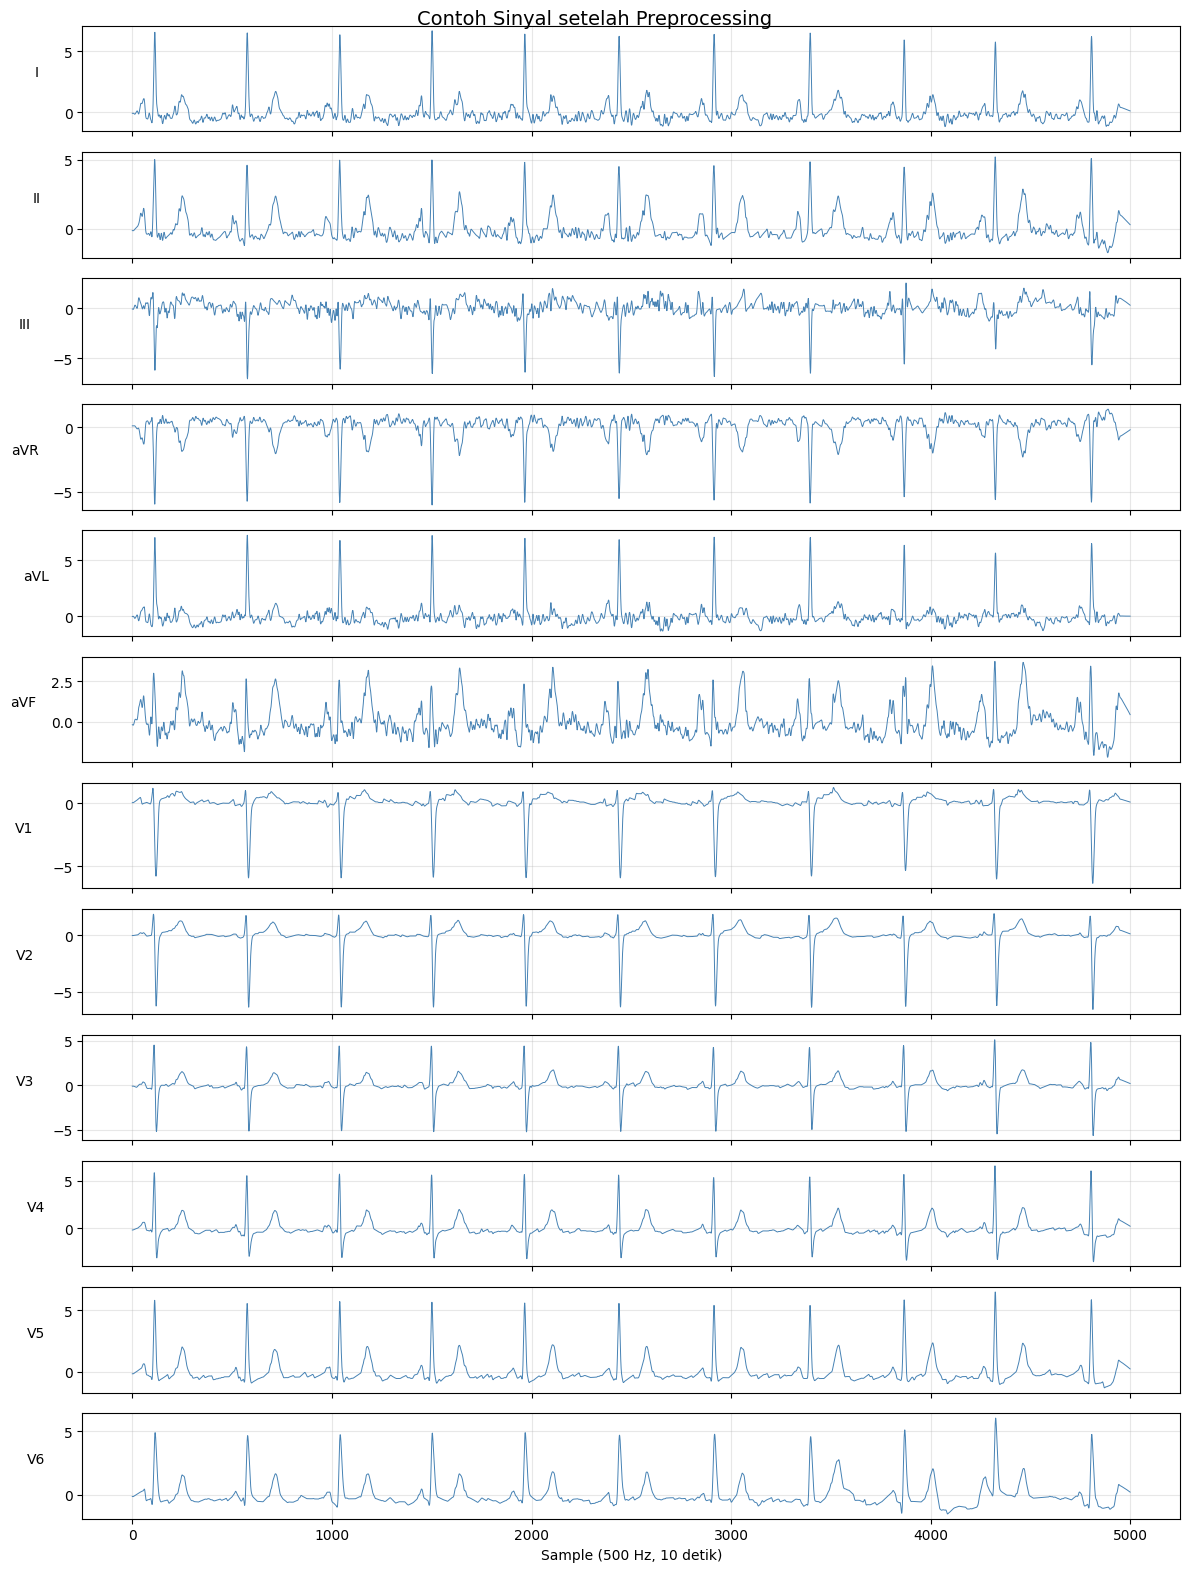

In [10]:
def bandpass_filter(signal, fs=TARGET_FS, lowcut=FILTER_LOWCUT,
                    highcut=FILTER_HIGHCUT, order=FILTER_ORDER):
    nyq = 0.5 * fs
    b, a = butter(order, [lowcut/nyq, highcut/nyq], btype="band")
    return filtfilt(b, a, signal, axis=-1).astype(np.float32)


def resample_signal(signal, original_fs, target_fs):
    if original_fs == target_fs: return signal
    n = int(signal.shape[1] * target_fs / original_fs)
    return sps.resample(signal, n, axis=1)


def normalize_signal(signal):
    mean = signal.mean(axis=1, keepdims=True)
    std = signal.std(axis=1, keepdims=True) + 1e-8
    return (signal - mean) / std


def pad_or_crop(signal, target_length):
    _, length = signal.shape
    if length == target_length: return signal
    if length > target_length:
        start = (length - target_length) // 2
        return signal[:, start:start+target_length]
    pt = target_length - length
    return np.pad(signal, ((0,0),(pt//2, pt-pt//2)), mode="constant")


def load_and_preprocess(record_path):
    record = wfdb.rdrecord(record_path)
    signal = record.p_signal.T.astype(np.float32)
    signal = resample_signal(signal, record.fs, TARGET_FS)
    signal = pad_or_crop(signal, TARGET_LENGTH)
    signal = bandpass_filter(signal, TARGET_FS)
    return normalize_signal(signal).astype(np.float32)


def plot_ecg_sample(record_path, title="Contoh Sinyal ECG 12-Lead"):
    signal = load_and_preprocess(record_path)
    fig, axes = plt.subplots(12, 1, figsize=(12, 16), sharex=True)
    for i, lead in enumerate(LEAD_NAMES):
        axes[i].plot(signal[i], linewidth=0.7, color="steelblue")
        axes[i].set_ylabel(lead, rotation=0, labelpad=20)
        axes[i].grid(True, alpha=0.3)
    axes[-1].set_xlabel("Sample (500 Hz, 10 detik)")
    plt.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.savefig(os.path.join(RESULTS_DIR, "eda_contoh_sinyal.png"), dpi=120)
    plt.show()


plot_ecg_sample(df_ptbxl.iloc[0]["record_path"], "Contoh Sinyal setelah Preprocessing")


In [11]:
def check_data_quality(df, dataset_name, n_samples=100):
    import random as pyrandom
    sample_paths = pyrandom.sample(list(df["record_path"]), min(n_samples, len(df)))
    nan_count = flat_count = error_count = 0
    for path in sample_paths:
        try:
            sig = load_and_preprocess(path)
            if np.isnan(sig).any(): nan_count += 1
            if np.allclose(sig.std(axis=1), 0): flat_count += 1
        except Exception:
            error_count += 1
    print(f"[{dataset_name}] Diperiksa {len(sample_paths)} rekaman:")
    print(f"  NaN: {nan_count} | Flat: {flat_count} | Gagal: {error_count}")


check_data_quality(df_ptbxl, "PTB-XL")
check_data_quality(df_chapman, "Chapman-Shaoxing")


[PTB-XL] Diperiksa 100 rekaman:
  NaN: 0 | Flat: 0 | Gagal: 0
[Chapman-Shaoxing] Diperiksa 100 rekaman:
  NaN: 0 | Flat: 0 | Gagal: 0


---
# TAHAP 3: PREPROCESSING DAN SPLIT

Split per pasien menggunakan `GroupShuffleSplit` untuk mencegah patient leakage. Pasien yang sama tidak muncul di lebih dari satu subset.


In [12]:
def split_ptbxl_by_patient(df, train_frac=0.7, val_frac=0.15, seed=SEED):
    gss1 = GroupShuffleSplit(n_splits=1, test_size=1-train_frac, random_state=seed)
    train_idx, temp_idx = next(gss1.split(df, groups=df["patient_id"]))
    df_train = df.iloc[train_idx].reset_index(drop=True)
    df_temp = df.iloc[temp_idx].reset_index(drop=True)
    val_ratio = val_frac / (1-train_frac)
    gss2 = GroupShuffleSplit(n_splits=1, test_size=1-val_ratio, random_state=seed)
    val_idx, test_idx = next(gss2.split(df_temp, groups=df_temp["patient_id"]))
    return (df_train,
            df_temp.iloc[val_idx].reset_index(drop=True),
            df_temp.iloc[test_idx].reset_index(drop=True))


df_ptbxl_train, df_ptbxl_val, df_ptbxl_test = split_ptbxl_by_patient(df_ptbxl)

print(f"PTB-XL train        : {len(df_ptbxl_train):5d} rekaman | {df_ptbxl_train['patient_id'].nunique():5d} pasien")
print(f"PTB-XL val          : {len(df_ptbxl_val):5d} rekaman | {df_ptbxl_val['patient_id'].nunique():5d} pasien")
print(f"PTB-XL test internal: {len(df_ptbxl_test):5d} rekaman | {df_ptbxl_test['patient_id'].nunique():5d} pasien")
print(f"Chapman (external)  : {len(df_chapman):5d} rekaman")

train_ids = set(df_ptbxl_train["patient_id"])
val_ids = set(df_ptbxl_val["patient_id"])
test_ids = set(df_ptbxl_test["patient_id"])
print(f"Overlap pasien train<->val : {len(train_ids & val_ids)}")
print(f"Overlap pasien train<->test: {len(train_ids & test_ids)}")
print(f"Overlap pasien val<->test  : {len(val_ids & test_ids)}")


PTB-XL train        : 14483 rekaman | 12598 pasien
PTB-XL val          :  3113 rekaman |  2699 pasien
PTB-XL test internal:  3039 rekaman |  2701 pasien
Chapman (external)  :  9119 rekaman
Overlap pasien train<->val : 0
Overlap pasien train<->test: 0
Overlap pasien val<->test  : 0


---
# TAHAP 4: CLEAN DATASET

Filter label relevan, harmonisasi SNOMED-CT, validasi distribusi, cek kualitas sinyal, split per pasien.


In [13]:
print("=== Ringkasan Dataset Bersih ===")
print(f"PTB-XL total        : {len(df_ptbxl)}")
print(f"PTB-XL train        : {len(df_ptbxl_train)}")
print(f"PTB-XL val          : {len(df_ptbxl_val)}")
print(f"PTB-XL test internal: {len(df_ptbxl_test)}")
print(f"Chapman (external)  : {len(df_chapman)}")
print()
print("Distribusi kelas training:")
lm = np.stack(df_ptbxl_train["label_vec"].values)
for i, c in enumerate(CLASS_CODES):
    print(f"  {CLASS_NAMES[c]:6s}: {int(lm[:, i].sum()):5d} rekaman")


=== Ringkasan Dataset Bersih ===
PTB-XL total        : 20635
PTB-XL train        : 14483
PTB-XL val          : 3113
PTB-XL test internal: 3039
Chapman (external)  : 9119

Distribusi kelas training:
  AF    :  1076 rekaman
  LBBB  :   385 rekaman
  IAVB  :   558 rekaman
  SB    :   445 rekaman
  NSR   : 12291 rekaman
  STach :   596 rekaman


---
# TAHAP 5: FEATURE ENGINEERING (N/A)

Feature engineering manual tidak dilakukan karena arsitektur deep learning (Conv1d + Graph Attention) belajar fitur secara otomatis dari sinyal mentah end-to-end.

Yang tetap dilakukan sebagai preprocessing: resampling, bandpass filter, normalisasi, padding, harmonisasi label, augmentasi noise.


---
# TAHAP 6: AUGMENTASI DAN DATASET

Simulasi noise (baseline wander, powerline, muscle) dan missing-lead untuk skenario robustness.

Handling class imbalance:
- Weighted Random Sampling: bobot rekaman berdasarkan frekuensi kelas terlangka
- Softened pos_weight: rasio neg/pos dilunakkan dengan akar kuadrat


In [14]:
def signal_power(x): return np.mean(x ** 2)


def add_noise_at_snr(clean, noise, target_snr_db):
    p_s = signal_power(clean); p_n = signal_power(noise)
    ratio = 10 ** (target_snr_db / 10)
    scale = np.sqrt(p_s / (ratio * p_n + 1e-12))
    return clean + scale * noise


def gen_baseline_wander(n, fs, freq_range=(0.15, 0.3)):
    t = np.arange(n) / fs
    return np.sin(2*np.pi*np.random.uniform(*freq_range)*t + np.random.uniform(0, 2*np.pi))


def gen_powerline(n, fs, line_freq=50.0):
    t = np.arange(n) / fs
    return np.sin(2*np.pi*line_freq*t)


def gen_muscle(n): return np.random.randn(n)


def augment_ecg(ecg, fs=TARGET_FS, snr_db=5.0, noise_type="baseline_wander", missing_leads=None):
    n_leads, T = ecg.shape
    noisy = np.zeros_like(ecg)
    for lead in range(n_leads):
        if noise_type == "baseline_wander": noise = gen_baseline_wander(T, fs)
        elif noise_type == "powerline":      noise = gen_powerline(T, fs)
        elif noise_type == "muscle":         noise = gen_muscle(T)
        elif noise_type == "clean":          noise = np.zeros(T)
        else: raise ValueError(noise_type)
        noisy[lead] = add_noise_at_snr(ecg[lead], noise, snr_db)
    if missing_leads:
        noisy[missing_leads, :] = 0.0
    return noisy


MISSING_LEAD_SCENARIOS = {
    "full": [],
    "missing_v1": [LEAD_NAMES.index("V1")],
    "missing_limb": [LEAD_NAMES.index(l) for l in ["I","II","III","aVR","aVL","aVF"]],
    "missing_precordial": [LEAD_NAMES.index(l) for l in ["V1","V2","V3","V4","V5","V6"]],
    "missing_random_2": None,
}
def get_missing_leads(s):
    if s == "missing_random_2": return sorted(random.sample(range(N_LEADS), 2))
    return MISSING_LEAD_SCENARIOS[s]


### Preload Sinyal ke RAM

Semua sinyal dibaca dan di-preprocessing sekali di awal, disimpan di RAM sebagai array. Ini menghemat waktu signifikan karena tidak membaca file berulang tiap epoch.


In [15]:
def preload_signals(df, name="dataset"):
    print(f"Preload {name} ({len(df)} rekaman)...")
    signals = []
    for i, row in df.iterrows():
        signals.append(load_and_preprocess(row["record_path"]))
        if (i+1) % 3000 == 0: print(f"  {i+1}/{len(df)}")
    signals = np.stack(signals).astype(np.float32)
    print(f"  Selesai. Shape: {signals.shape}, memori: {signals.nbytes/1e9:.2f} GB")
    return signals


signals_train = preload_signals(df_ptbxl_train, "PTB-XL train")
signals_val = preload_signals(df_ptbxl_val, "PTB-XL val")
signals_test = preload_signals(df_ptbxl_test, "PTB-XL test internal")
signals_chapman = preload_signals(df_chapman, "Chapman")


Preload PTB-XL train (14483 rekaman)...
  3000/14483
  6000/14483
  9000/14483
  12000/14483
  Selesai. Shape: (14483, 12, 5000), memori: 3.48 GB
Preload PTB-XL val (3113 rekaman)...
  3000/3113
  Selesai. Shape: (3113, 12, 5000), memori: 0.75 GB
Preload PTB-XL test internal (3039 rekaman)...
  3000/3039
  Selesai. Shape: (3039, 12, 5000), memori: 0.73 GB
Preload Chapman (9119 rekaman)...
  3000/9119
  6000/9119
  9000/9119
  Selesai. Shape: (9119, 12, 5000), memori: 2.19 GB


In [16]:
class ECGDataset(Dataset):
    def __init__(self, signals, labels, augment=False, snr_db=5.0,
                 noise_type="baseline_wander", missing_lead_scenario="full"):
        self.signals = signals; self.labels = labels
        self.augment = augment; self.snr_db = snr_db
        self.noise_type = noise_type; self.missing_lead_scenario = missing_lead_scenario
    def __len__(self): return len(self.signals)
    def __getitem__(self, idx):
        signal = self.signals[idx].copy()
        if self.augment:
            missing = get_missing_leads(self.missing_lead_scenario)
            eff = "clean" if self.noise_type == "no_noise" else self.noise_type
            signal = augment_ecg(signal, fs=TARGET_FS, snr_db=self.snr_db,
                                  noise_type=eff, missing_leads=missing)
        return (torch.from_numpy(signal.astype(np.float32)),
                torch.from_numpy(self.labels[idx].astype(np.float32)))


def build_dataloader(ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, sampler=None):
    if sampler is not None:
        return DataLoader(ds, batch_size=batch_size, sampler=sampler,
                           num_workers=num_workers, pin_memory=True)
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle,
                       num_workers=num_workers, pin_memory=True)


def compute_sample_weights(labels):
    inv = 1.0 / np.clip(labels.sum(axis=0), 1, None)
    w = np.zeros(len(labels), dtype=np.float32)
    for i, vec in enumerate(labels):
        present = np.where(vec > 0)[0]
        w[i] = inv[present].max()
    return w


def build_weighted_sampler(labels):
    w = compute_sample_weights(labels)
    return torch.utils.data.WeightedRandomSampler(torch.from_numpy(w).double(), len(labels), replacement=True)


def compute_pos_weight_softened(labels, device, power=0.5):
    pos = labels.sum(axis=0); neg = len(labels) - pos
    return torch.tensor((neg / np.clip(pos, 1, None)) ** power, dtype=torch.float32, device=device)


labels_train = np.stack(df_ptbxl_train["label_vec"].values)
labels_val = np.stack(df_ptbxl_val["label_vec"].values)
labels_test = np.stack(df_ptbxl_test["label_vec"].values)
labels_chapman = np.stack(df_chapman["label_vec"].values)

train_ds = ECGDataset(signals_train, labels_train)
val_ds = ECGDataset(signals_val, labels_val)
test_internal_ds = ECGDataset(signals_test, labels_test)
test_external_ds = ECGDataset(signals_chapman, labels_chapman)

train_sampler = build_weighted_sampler(labels_train)

train_loader = build_dataloader(train_ds, sampler=train_sampler)
val_loader = build_dataloader(val_ds)
test_internal_loader = build_dataloader(test_internal_ds)
test_external_loader = build_dataloader(test_external_ds)
print("DataLoaders siap.")


DataLoaders siap.


---
# TAHAP 7: MODEL DEVELOPMENT

Tiga arsitektur:
- **CNNBaseline** - 1D-CNN konvensional (Conv1d)
- **TransformerBaseline** - Transformer ringan dengan patch embedding
- **NC-GAT** - residual encoder per-lead + 3 GAT layer + LayerNorm + temporal attention pooling + classifier


In [17]:
class GraphAttentionLayer(nn.Module):
    def __init__(self, in_dim, out_dim, n_heads=4, dropout=0.1, concat=True):
        super().__init__()
        self.n_heads = n_heads; self.out_dim = out_dim; self.concat = concat
        self.W = nn.Linear(in_dim, out_dim * n_heads, bias=False)
        self.a_src = nn.Parameter(torch.empty(n_heads, out_dim))
        self.a_dst = nn.Parameter(torch.empty(n_heads, out_dim))
        nn.init.xavier_uniform_(self.a_src); nn.init.xavier_uniform_(self.a_dst)
        self.leaky = nn.LeakyReLU(0.2); self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        B, N, _ = x.shape
        h = self.W(x).view(B, N, self.n_heads, self.out_dim).permute(0, 2, 1, 3)
        src = (h * self.a_src.view(1, self.n_heads, 1, self.out_dim)).sum(-1)
        dst = (h * self.a_dst.view(1, self.n_heads, 1, self.out_dim)).sum(-1)
        e = self.leaky(src.unsqueeze(-1) + dst.unsqueeze(-2))
        alpha = self.dropout(torch.softmax(e, dim=-1))
        out = torch.matmul(alpha, h)
        if self.concat:
            out = out.permute(0, 2, 1, 3).reshape(B, N, self.n_heads * self.out_dim)
        else:
            out = out.mean(dim=1)
        return out, alpha


class PerLeadResidualBlock(nn.Module):
    def __init__(self, in_ch, out_ch, kernel_size=7, stride=2, dropout=0.1):
        super().__init__()
        self.conv1 = nn.Conv1d(in_ch, out_ch, kernel_size, stride=stride, padding=kernel_size//2)
        self.bn1 = nn.BatchNorm1d(out_ch)
        self.conv2 = nn.Conv1d(out_ch, out_ch, kernel_size, padding=kernel_size//2)
        self.bn2 = nn.BatchNorm1d(out_ch)
        self.dropout = nn.Dropout(dropout)
        self.skip = nn.Sequential()
        if stride != 1 or in_ch != out_ch:
            self.skip = nn.Sequential(nn.Conv1d(in_ch, out_ch, 1, stride=stride), nn.BatchNorm1d(out_ch))
        self.relu = nn.ReLU(inplace=True)

    def forward(self, x):
        identity = self.skip(x)
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out = self.dropout(out)
        return self.relu(out + identity)


class PerLeadResidualEncoder(nn.Module):
    def __init__(self, channels=(64, 128, 128), dropout=0.1):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv1d(1, channels[0], 15, stride=2, padding=7),
                                  nn.BatchNorm1d(channels[0]), nn.ReLU(inplace=True))
        self.stage1 = PerLeadResidualBlock(channels[0], channels[0], stride=2, dropout=dropout)
        self.stage2 = PerLeadResidualBlock(channels[0], channels[1], stride=2, dropout=dropout)
        self.stage3 = PerLeadResidualBlock(channels[1], channels[2], stride=2, dropout=dropout)
    def forward(self, x):
        B, N, T = x.shape
        x = x.reshape(B*N, 1, T)
        x = self.stem(x); x = self.stage1(x); x = self.stage2(x); x = self.stage3(x)
        return x.view(B, N, x.shape[1], x.shape[2])


class TemporalAttentionPooling(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.attn = nn.Sequential(nn.Linear(dim, dim//2), nn.Tanh(), nn.Linear(dim//2, 1))
    def forward(self, x):
        B, N, D, T = x.shape
        x_t = x.permute(0, 1, 3, 2)
        w = torch.softmax(self.attn(x_t), dim=2)
        return (x_t * w).sum(dim=2)


class NCGAT(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES, cnn_channels=(64, 128, 128),
                 gat_hidden=64, gat_heads=8, n_gat_layers=3, dropout=DROPOUT):
        super().__init__()
        self.encoder = PerLeadResidualEncoder(cnn_channels, dropout=dropout)
        self.gat_layers = nn.ModuleList()
        in_dim = cnn_channels[-1]
        for i in range(n_gat_layers - 1):
            self.gat_layers.append(GraphAttentionLayer(in_dim, gat_hidden, gat_heads, dropout, concat=True))
            self.gat_layers.append(nn.LayerNorm(gat_hidden * gat_heads))
            in_dim = gat_hidden * gat_heads
        self.gat_layers.append(GraphAttentionLayer(in_dim, gat_hidden, gat_heads, dropout, concat=False))
        self.gat_layers.append(nn.LayerNorm(gat_hidden))
        self.elu = nn.ELU()
        self.temporal_pool = TemporalAttentionPooling(gat_hidden)
        self.classifier = nn.Sequential(
            nn.Linear(gat_hidden, 128), nn.ReLU(inplace=True),
            nn.Dropout(dropout), nn.Linear(128, num_classes))

    def forward(self, x, return_attention=False):
        B = x.shape[0]
        feat = self.encoder(x)
        N, C, T_out = feat.shape[1], feat.shape[2], feat.shape[3]
        feat = feat.permute(0, 3, 1, 2).reshape(B*T_out, N, C)
        h = feat; last_alpha = None
        for i, layer in enumerate(self.gat_layers):
            if isinstance(layer, GraphAttentionLayer):
                h, alpha = layer(h)
                if i == len(self.gat_layers) - 2: last_alpha = alpha
                if i < len(self.gat_layers) - 2: h = self.elu(h)
            else:
                h = layer(h)
        h = h.view(B, T_out, N, -1).permute(0, 2, 3, 1)
        node_embed = self.temporal_pool(h)
        graph_embed = node_embed.mean(dim=1)
        logits = self.classifier(graph_embed)
        if return_attention:
            last_alpha = last_alpha.view(B, T_out, last_alpha.shape[1], N, N).mean(dim=1)
            return logits, last_alpha
        return logits


class CNNBaseline(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES, channels=(64, 128, 256, 256), dropout=0.2):
        super().__init__()
        layers = []; in_ch = N_LEADS
        for out_ch in channels:
            layers += [nn.Conv1d(in_ch, out_ch, 15, stride=2, padding=7),
                       nn.BatchNorm1d(out_ch), nn.ReLU(inplace=True), nn.Dropout(dropout)]
            in_ch = out_ch
        self.conv = nn.Sequential(*layers)
        self.pool = nn.AdaptiveAvgPool1d(1)
        self.classifier = nn.Linear(channels[-1], num_classes)
    def forward(self, x):
        return self.classifier(self.pool(self.conv(x)).squeeze(-1))


class TransformerBaseline(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES, patch_size=25, d_model=128,
                 n_heads=4, n_layers=2, dropout=0.2):
        super().__init__()
        self.patch_embed = nn.Conv1d(N_LEADS, d_model, patch_size, stride=patch_size)
        self.pos_embed = nn.Parameter(torch.randn(1, TARGET_LENGTH//patch_size + 1, d_model) * 0.02)
        encoder_layer = nn.TransformerEncoderLayer(d_model, n_heads, d_model*2, dropout, batch_first=True)
        self.transformer = nn.TransformerEncoder(encoder_layer, n_layers)
        self.classifier = nn.Linear(d_model, num_classes)
    def forward(self, x):
        tokens = self.patch_embed(x).permute(0, 2, 1)
        tokens = tokens + self.pos_embed[:, :tokens.shape[1], :]
        return self.classifier(self.transformer(tokens).mean(dim=1))


def self_test_models():
    x = torch.randn(4, N_LEADS, TARGET_LENGTH)
    print("Self-test arsitektur:")
    for name, M in [("CNN", CNNBaseline), ("Transformer", TransformerBaseline), ("NC-GAT", NCGAT)]:
        m = M(); out = m(x)
        assert out.shape == (4, NUM_CLASSES), f"{name} shape salah: {out.shape}"
        n_params = sum(p.numel() for p in m.parameters())
        print(f"  {name:12s}  output={tuple(out.shape)}  params={n_params:,}")


self_test_models()


Self-test arsitektur:
  CNN           output=(4, 6)  params=1,612,614
  Transformer   output=(4, 6)  params=329,990
  NC-GAT        output=(4, 6)  params=1,097,735


---
# TAHAP 8: TRAINING

Konfigurasi:
- Loss: Focal Loss + Label Smoothing (gamma=2.0, alpha=0.25, smoothing=0.05)
- Optimizer: AdamW (lr=1e-3, weight decay=5e-5)
- Scheduler: warmup 5 epoch + cosine annealing
- Early stopping: patience 7, max epoch 25
- Checkpoint disimpan setiap epoch terbaik

NC-GAT dilatih dengan noise-consistency: `L_total = L_cls(clean) + lambda * MSE(pred_clean, pred_noisy)`.


In [18]:
class FocalBCELossWithSmoothing(nn.Module):
    def __init__(self, pos_weight=None, gamma=2.0, alpha=0.25, smoothing=0.05):
        super().__init__()
        self.pos_weight = pos_weight
        self.gamma = gamma; self.alpha = alpha; self.smoothing = smoothing

    def forward(self, logits, targets):
        targets_smooth = targets * (1 - self.smoothing) + (1 - targets) * self.smoothing
        bce = F.binary_cross_entropy_with_logits(logits, targets_smooth,
                                                  pos_weight=self.pos_weight, reduction="none")
        p = torch.sigmoid(logits)
        p_t = p * targets + (1 - p) * (1 - targets)
        focal_w = (1 - p_t) ** self.gamma
        alpha_t = self.alpha * targets + (1 - self.alpha) * (1 - targets)
        return (alpha_t * focal_w * bce).mean()


def compute_metrics(y_true, y_prob, threshold=0.5):
    if np.isscalar(threshold):
        y_pred = (y_prob >= threshold).astype(int)
    else:
        y_pred = (y_prob >= threshold.reshape(1, -1)).astype(int)
    m = {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "recall": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "micro_f1": f1_score(y_true, y_pred, average="micro", zero_division=0),
    }
    try: m["auroc_macro"] = roc_auc_score(y_true, y_prob, average="macro")
    except ValueError: m["auroc_macro"] = float("nan")
    try: m["auprc_macro"] = average_precision_score(y_true, y_prob, average="macro")
    except ValueError: m["auprc_macro"] = float("nan")
    return m


def find_best_thresholds(y_true, y_prob, grid=np.arange(0.05, 0.96, 0.05)):
    thresholds = np.full(y_true.shape[1], 0.5)
    for c in range(y_true.shape[1]):
        best_f1, best_t = 0.0, 0.5
        for t in grid:
            f1 = f1_score(y_true[:, c], (y_prob[:, c] >= t).astype(int), zero_division=0)
            if f1 > best_f1: best_f1, best_t = f1, t
        thresholds[c] = best_t
    return thresholds


def train_one_epoch(model, loader, opt, crit, device):
    model.train(); tot = 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        opt.zero_grad()
        loss = crit(model(x), y)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
        opt.step()
        tot += loss.item() * x.size(0)
    return tot / len(loader.dataset)


def train_one_epoch_nc(model, loader, opt, crit, device, lam=1.0, snr_db=5.0):
    model.train(); tot = 0
    scenarios = ["full", "full", "missing_v1", "missing_limb", "missing_random_2"]
    for x_clean, y in loader:
        x_clean, y = x_clean.to(device), y.to(device)
        x_noisy = x_clean.clone().cpu().numpy()
        for i in range(x_noisy.shape[0]):
            nt = random.choice(["baseline_wander", "muscle", "powerline"])
            sc = random.choice(scenarios)
            x_noisy[i] = augment_ecg(x_noisy[i], fs=TARGET_FS, snr_db=snr_db,
                                      noise_type=nt, missing_leads=get_missing_leads(sc))
        x_noisy = torch.from_numpy(x_noisy).to(device)
        opt.zero_grad()
        logits_c = model(x_clean); logits_n = model(x_noisy)
        loss_cls = crit(logits_c, y)
        loss_cons = F.mse_loss(torch.sigmoid(logits_c), torch.sigmoid(logits_n))
        loss = loss_cls + lam * loss_cons
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
        opt.step()
        tot += loss.item() * x_clean.size(0)
    return tot / len(loader.dataset)


@torch.no_grad()
def evaluate_model(model, loader, device):
    model.eval(); probs, labels = [], []
    for x, y in loader:
        probs.append(torch.sigmoid(model(x.to(device))).cpu().numpy())
        labels.append(y.numpy())
    y_prob = np.concatenate(probs); y_true = np.concatenate(labels)
    return compute_metrics(y_true, y_prob), y_true, y_prob


def run_training(model, train_loader, val_loader, device, model_name="model",
                  epochs=EPOCHS, lr=LR, use_noise_consistency=False, lam=1.0,
                  patience=PATIENCE, pos_weight_power=0.5, warmup_epochs=WARMUP_EPOCHS,
                  weight_decay=WEIGHT_DECAY):
    model = model.to(device)
    pos_w = compute_pos_weight_softened(labels_train, device, pos_weight_power)
    crit = FocalBCELossWithSmoothing(pos_weight=pos_w, gamma=1.5, alpha=0.25, smoothing=0.05)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)

    def lr_lambda(ep):
        if ep < warmup_epochs: return (ep + 1) / warmup_epochs
        progress = (ep - warmup_epochs) / max(1, epochs - warmup_epochs)
        return 0.5 * (1 + math.cos(math.pi * progress))
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lr_lambda)

    history = {"loss": [], "val_f1": [], "val_auroc": []}
    top_states = []  # mini-SWA: simpan top-3 state
    best_f1, no_improve = -1, 0
    for ep in range(epochs):
        if use_noise_consistency:
            tl = train_one_epoch_nc(model, train_loader, opt, crit, device, lam)
        else:
            tl = train_one_epoch(model, train_loader, opt, crit, device)
        sched.step()
        vm, _, _ = evaluate_model(model, val_loader, device)
        vf1 = vm["macro_f1"]
        history["loss"].append(tl); history["val_f1"].append(vf1); history["val_auroc"].append(vm["auroc_macro"])
        print(f"Epoch {ep+1:02d}/{epochs}  loss={tl:.4f}  val_f1={vf1:.4f}  val_auroc={vm['auroc_macro']:.4f}")
        if vf1 > best_f1:
            best_f1 = vf1
            state = {k: v.clone() for k, v in model.state_dict().items()}
            torch.save(state, os.path.join(CHECKPOINT_DIR, f"{model_name}.pt"))
            top_states.append(state)
            if len(top_states) > 3: top_states.pop(0)
            no_improve = 0
        else:
            no_improve += 1
            if no_improve >= patience:
                print(f"Early stopping epoch {ep+1}")
                break
    # Mini-SWA: rata-rata top-3 state
    if len(top_states) >= 2:
        avg_state = {}
        for k in top_states[0].keys():
            avg_state[k] = torch.stack([s[k].float() for s in top_states], dim=0).mean(dim=0)
        torch.save(avg_state, os.path.join(CHECKPOINT_DIR, f"{model_name}_swa.pt"))
        model.load_state_dict(avg_state)
    else:
        model.load_state_dict(top_states[0])
    return model, best_f1, history


In [20]:
import gc
torch.cuda.empty_cache(); gc.collect()

trained_models = {}
thresholds_per_model = {}
agg_results_a = {}
histories_a = {}

model_configs = {
    "CNN": {"cls": CNNBaseline, "kwargs": {}},
    "Transformer": {"cls": TransformerBaseline, "kwargs": {}},
    "GAT": {"cls": NCGAT, "kwargs": {"gat_hidden": 64, "gat_heads": 8, "n_gat_layers": 3}},
}

for name, cfg in model_configs.items():
    model = cfg["cls"](**cfg["kwargs"])
    state_path = os.path.join(CHECKPOINT_DIR, f"baseline_{name.lower()}_swa.pt")
    model.load_state_dict(torch.load(state_path, map_location="cpu"))
    model = model.to(DEVICE)          # <-- WAJIB: pindahkan model ke GPU
    model.eval()
    trained_models[name] = model
    
    _, yv, pv = evaluate_model(model, val_loader, DEVICE)
    thresholds_per_model[name] = find_best_thresholds(yv, pv)
    
    _, yt, pt = evaluate_model(model, test_internal_loader, DEVICE)
    m = compute_metrics(yt, pt, threshold=thresholds_per_model[name])
    agg_results_a[name] = {"mean": m, "std": {k: 0.0 for k in m}, "per_seed": [m]}
    histories_a[name] = [{"loss": [0], "val_f1": [m["macro_f1"]], "val_auroc": [m["auroc_macro"]]}]
    print(f"  {name}: macro-F1 = {m['macro_f1']:.4f}")

free, total = torch.cuda.mem_get_info()
print(f"\nVRAM: {free/1e9:.2f} GB free / {total/1e9:.2f} GB total")

rows = []
for name, agg in agg_results_a.items():
    row = {"model": name}
    for k in ["accuracy","precision","recall","macro_f1","micro_f1","auroc_macro","auprc_macro"]:
        row[k] = f"{agg['mean'][k]:.4f}"
    rows.append(row)
df_results_a = pd.DataFrame(rows).set_index("model")
print("\n=== Hasil Eksperimen A (rekonstruksi) ===")
print(df_results_a)
df_results_a.to_csv(os.path.join(RESULTS_DIR, "eksperimen_a_baseline.csv"))

  CNN: macro-F1 = 0.7398
  Transformer: macro-F1 = 0.6091
  GAT: macro-F1 = 0.7746

VRAM: 12.64 GB free / 15.64 GB total

=== Hasil Eksperimen A (rekonstruksi) ===
            accuracy precision  recall macro_f1 micro_f1 auroc_macro  \
model                                                                  
CNN           0.8562    0.6988  0.7985   0.7398   0.9095      0.9682   
Transformer   0.7246    0.5572  0.7019   0.6091   0.8397      0.9062   
GAT           0.8806    0.7529  0.8132   0.7746   0.9243      0.9779   

            auprc_macro  
model                    
CNN              0.7794  
Transformer      0.6262  
GAT              0.8162  


## Eksperimen A - Baseline

In [ ]:
model_configs = {
    "CNN":         {"cls": CNNBaseline, "kwargs": {}},
    "Transformer": {"cls": TransformerBaseline, "kwargs": {}},
    "GAT":         {"cls": NCGAT, "kwargs": {"gat_hidden": 64, "gat_heads": 8, "n_gat_layers": 3}},
}

trained_models, agg_results_a, thresholds_per_model, histories_a = {}, {}, {}, {}

for name, cfg in model_configs.items():
    print(f"\n{'='*60}\nTraining {name}\n{'='*60}")
    torch.manual_seed(SEED); np.random.seed(SEED); random.seed(SEED)
    model = cfg["cls"](**cfg["kwargs"])
    model, val_f1, hist = run_training(model, train_loader, val_loader, DEVICE,
        model_name=f"baseline_{name.lower()}", epochs=EPOCHS, lr=LR, patience=PATIENCE)
    _, yv, pv = evaluate_model(model, val_loader, DEVICE)
    th = find_best_thresholds(yv, pv)
    _, yt, pt = evaluate_model(model, test_internal_loader, DEVICE)
    m = compute_metrics(yt, pt, threshold=th)
    trained_models[name] = model
    agg_results_a[name] = {"mean": m, "std": {k: 0.0 for k in m}, "per_seed": [m]}
    thresholds_per_model[name] = th
    histories_a[name] = [hist]

rows = []
for name, agg in agg_results_a.items():
    row = {"model": name}
    for k in ["accuracy","precision","recall","macro_f1","micro_f1","auroc_macro","auprc_macro"]:
        row[k] = f"{agg['mean'][k]:.4f}"
    rows.append(row)
df_results_a = pd.DataFrame(rows).set_index("model")
print("\n=== Hasil Eksperimen A ===")
print(df_results_a)


## Eksperimen C - NC-GAT (noise-consistency)

In [21]:
import gc
torch.cuda.empty_cache(); gc.collect()

free, total = torch.cuda.mem_get_info()
print(f"VRAM sebelum NC-GAT: {free/1e9:.2f} GB free / {total/1e9:.2f} GB total")

train_loader_nc = build_dataloader(train_ds, batch_size=32, sampler=train_sampler)
val_loader_nc = build_dataloader(val_ds, batch_size=32)

print(f"\n{'='*60}\nTraining NC-GAT (noise-consistency, batch=32)\n{'='*60}")
torch.manual_seed(SEED); np.random.seed(SEED); random.seed(SEED)

model_gat_nc = NCGAT(gat_hidden=64, gat_heads=8, n_gat_layers=3, dropout=DROPOUT)
model_gat_nc, val_f1_nc, hist_nc = run_training(
    model_gat_nc, train_loader_nc, val_loader_nc, DEVICE,
    model_name="ncgat_with_consistency",
    epochs=EPOCHS, lr=LR, patience=PATIENCE,
    use_noise_consistency=True, lam=1.0)

_, yv_nc, pv_nc = evaluate_model(model_gat_nc, val_loader, DEVICE)
thresholds_gat_nc = find_best_thresholds(yv_nc, pv_nc)
_, yt_nc_full, pt_nc_full = evaluate_model(model_gat_nc, test_internal_loader, DEVICE)
m_nc = compute_metrics(yt_nc_full, pt_nc_full, threshold=thresholds_gat_nc)

trained_models["NC-GAT"] = model_gat_nc
agg_results_a["NC-GAT"] = {"mean": m_nc, "std": {k: 0.0 for k in m_nc}, "per_seed": [m_nc]}
thresholds_per_model["NC-GAT"] = thresholds_gat_nc
histories_nc = [hist_nc]

print(f"\n{'='*60}")
print("Threshold NC-GAT:", dict(zip(CLASS_NAMES_ORDERED, thresholds_gat_nc.round(2))))
print("Hasil NC-GAT:", {k: round(v, 4) for k, v in m_nc.items()})
print(f"{'='*60}")

VRAM sebelum NC-GAT: 15.40 GB free / 15.64 GB total

Training NC-GAT (noise-consistency, batch=32)
Epoch 01/25  loss=0.1029  val_f1=0.4010  val_auroc=0.9247
Epoch 02/25  loss=0.0578  val_f1=0.6198  val_auroc=0.9751
Epoch 03/25  loss=0.0483  val_f1=0.5730  val_auroc=0.9670
Epoch 04/25  loss=0.0453  val_f1=0.5348  val_auroc=0.9659
Epoch 05/25  loss=0.0422  val_f1=0.4774  val_auroc=0.9732
Epoch 06/25  loss=0.0376  val_f1=0.6204  val_auroc=0.9790
Epoch 07/25  loss=0.0335  val_f1=0.6783  val_auroc=0.9770
Epoch 08/25  loss=0.0324  val_f1=0.6549  val_auroc=0.9781
Epoch 09/25  loss=0.0295  val_f1=0.6233  val_auroc=0.9776
Epoch 10/25  loss=0.0278  val_f1=0.6272  val_auroc=0.9790
Epoch 11/25  loss=0.0269  val_f1=0.6986  val_auroc=0.9837
Epoch 12/25  loss=0.0248  val_f1=0.7128  val_auroc=0.9803
Epoch 13/25  loss=0.0235  val_f1=0.6652  val_auroc=0.9791
Epoch 14/25  loss=0.0212  val_f1=0.6950  val_auroc=0.9808
Epoch 15/25  loss=0.0190  val_f1=0.6839  val_auroc=0.9800
Epoch 16/25  loss=0.0177  val_f

---
# TAHAP 9: MODEL EVALUATION

Metrik: Accuracy, Precision (macro), Recall (macro), F1 (macro, micro), AUROC (macro), AUPRC (macro).


### Tabel Perbandingan Model

In [22]:
rows = []
for name, agg in agg_results_a.items():
    row = {"model": name}
    for k in ["accuracy","precision","recall","macro_f1","micro_f1","auroc_macro","auprc_macro"]:
        row[k] = f"{agg['mean'][k]:.4f}"
    rows.append(row)
df_final = pd.DataFrame(rows).set_index("model")
print("=== Tabel Perbandingan Model (Test Internal PTB-XL) ===")
print(df_final)
df_final.to_csv(os.path.join(RESULTS_DIR, "tabel_final.csv"))


=== Tabel Perbandingan Model (Test Internal PTB-XL) ===
            accuracy precision  recall macro_f1 micro_f1 auroc_macro  \
model                                                                  
CNN           0.8562    0.6988  0.7985   0.7398   0.9095      0.9682   
Transformer   0.7246    0.5572  0.7019   0.6091   0.8397      0.9062   
GAT           0.8806    0.7529  0.8132   0.7746   0.9243      0.9779   
NC-GAT        0.8901    0.7657  0.8222   0.7894   0.9293      0.9802   

            auprc_macro  
model                    
CNN              0.7794  
Transformer      0.6262  
GAT              0.8162  
NC-GAT           0.8291  


### Bootstrap 95% Confidence Interval

Untuk menambah validitas statistik tanpa multi-seed training, kita hitung **bootstrap 95% CI** untuk macro-F1. Metode: resample test set dengan replacement 1000 kali, hitung F1 tiap resample, ambil percentile 2.5% dan 97.5%.


In [23]:
def bootstrap_ci(y_true, y_prob, threshold, metric_fn, n_bootstrap=1000, alpha=0.05, seed=42):
    rng = np.random.RandomState(seed)
    n = len(y_true)
    scores = []
    for _ in range(n_bootstrap):
        idx = rng.randint(0, n, n)
        if np.isscalar(threshold):
            y_pred = (y_prob[idx] >= threshold).astype(int)
        else:
            y_pred = (y_prob[idx] >= threshold.reshape(1, -1)).astype(int)
        scores.append(metric_fn(y_true[idx], y_pred))
    scores = np.array(scores)
    lower = np.percentile(scores, 100 * alpha / 2)
    upper = np.percentile(scores, 100 * (1 - alpha / 2))
    return scores.mean(), lower, upper


# Bootstrap CI untuk macro-F1 tiap model
boot_results = {}
for name in trained_models.keys():
    _, yt, pt = evaluate_model(trained_models[name], test_internal_loader, DEVICE)
    th = thresholds_per_model[name]
    f1_fn = lambda yt, yp: f1_score(yt, yp, average="macro", zero_division=0)
    mean, lo, hi = bootstrap_ci(yt, pt, th, f1_fn, n_bootstrap=1000)
    boot_results[name] = {"macro_f1_mean": mean, "ci_lower": lo, "ci_upper": hi}
    print(f"{name:12s}  macro-F1 = {mean:.4f}  (95% CI: {lo:.4f} - {hi:.4f})")

df_boot = pd.DataFrame(boot_results).T
df_boot.to_csv(os.path.join(RESULTS_DIR, "bootstrap_ci.csv"))
print()
print(df_boot.round(4))


CNN           macro-F1 = 0.7392  (95% CI: 0.7165 - 0.7613)
Transformer   macro-F1 = 0.6083  (95% CI: 0.5848 - 0.6312)
GAT           macro-F1 = 0.7742  (95% CI: 0.7501 - 0.7960)
NC-GAT        macro-F1 = 0.7889  (95% CI: 0.7658 - 0.8100)

             macro_f1_mean  ci_lower  ci_upper
CNN                 0.7392    0.7165    0.7613
Transformer         0.6083    0.5848    0.6312
GAT                 0.7742    0.7501    0.7960
NC-GAT              0.7889    0.7658    0.8100


### McNemar Test: GAT vs NC-GAT

Uji signifikansi statistik apakah NC-GAT berbeda signifikan dari GAT baseline. McNemar test membandingkan pola kesalahan dari dua model pada test set yang sama.


In [24]:
from scipy.stats import chi2

def mcnemar_test(y_true, prob_a, prob_b, threshold_a, threshold_b):
    if np.isscalar(threshold_a):
        pred_a = (prob_a >= threshold_a).astype(int)
    else:
        pred_a = (prob_a >= threshold_a.reshape(1, -1)).astype(int)
    if np.isscalar(threshold_b):
        pred_b = (prob_b >= threshold_b).astype(int)
    else:
        pred_b = (prob_b >= threshold_b.reshape(1, -1)).astype(int)
    correct_a = (pred_a == y_true).all(axis=1)
    correct_b = (pred_b == y_true).all(axis=1)
    b = np.sum(correct_a & ~correct_b)
    c = np.sum(~correct_a & correct_b)
    if b + c == 0:
        return 0.0, 1.0
    chi2_stat = (abs(b - c) - 1) ** 2 / (b + c)
    p_value = 1 - chi2.cdf(chi2_stat, df=1)
    return chi2_stat, p_value


_, yt_gat, pt_gat = evaluate_model(trained_models["GAT"], test_internal_loader, DEVICE)
_, yt_nc, pt_nc = evaluate_model(trained_models["NC-GAT"], test_internal_loader, DEVICE)

chi2_stat, p_value = mcnemar_test(yt_gat, pt_gat, pt_nc,
                                   thresholds_per_model["GAT"], thresholds_per_model["NC-GAT"])
print(f"McNemar test GAT vs NC-GAT:")
print(f"  Chi-square = {chi2_stat:.4f}")
print(f"  p-value    = {p_value:.4f}")
if p_value < 0.05:
    print(f"  Kesimpulan : Perbedaan SIGNIFIKAN (p < 0.05)")
else:
    print(f"  Kesimpulan : Perbedaan TIDAK signifikan (p >= 0.05)")


McNemar test GAT vs NC-GAT:
  Chi-square = 4.1481
  p-value    = 0.0417
  Kesimpulan : Perbedaan SIGNIFIKAN (p < 0.05)


### Confusion Matrix per Kelas

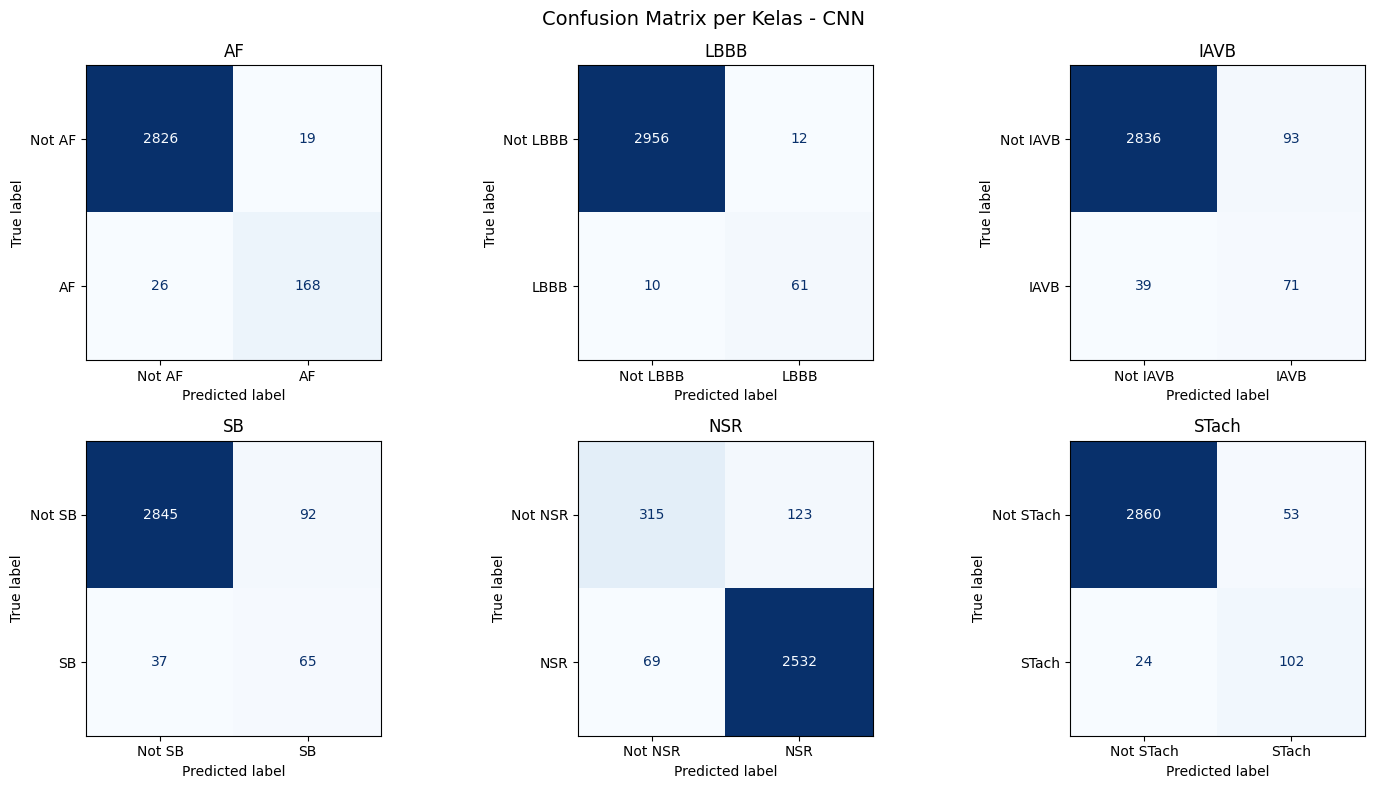

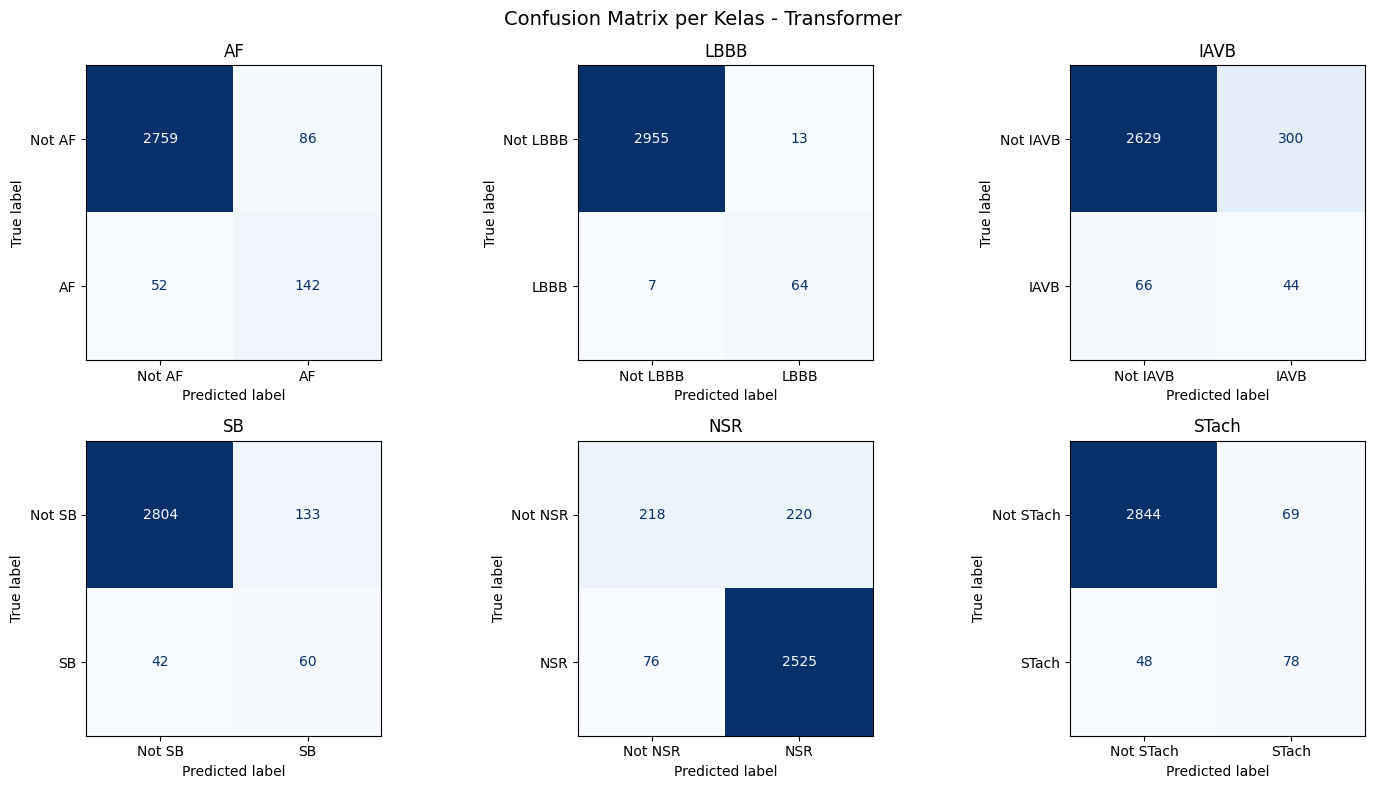

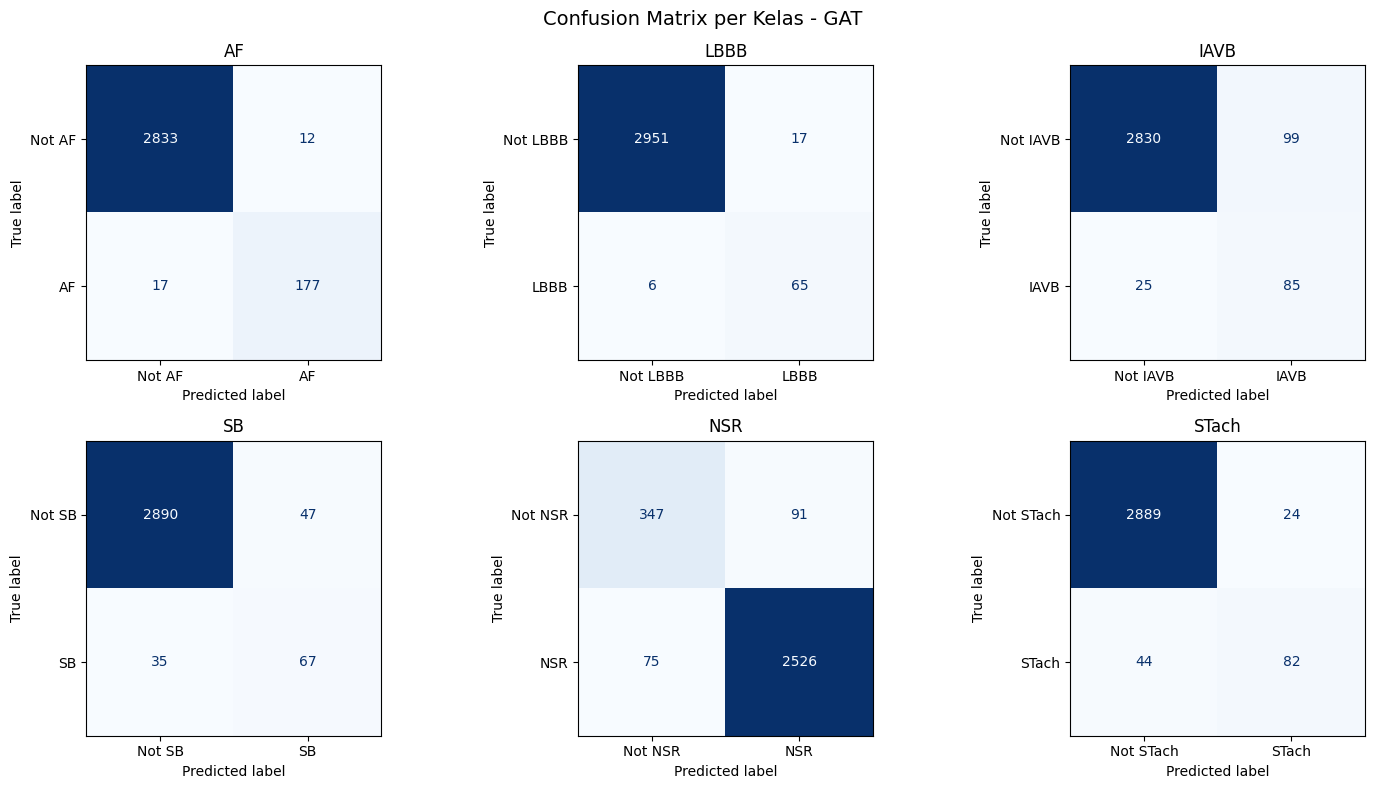

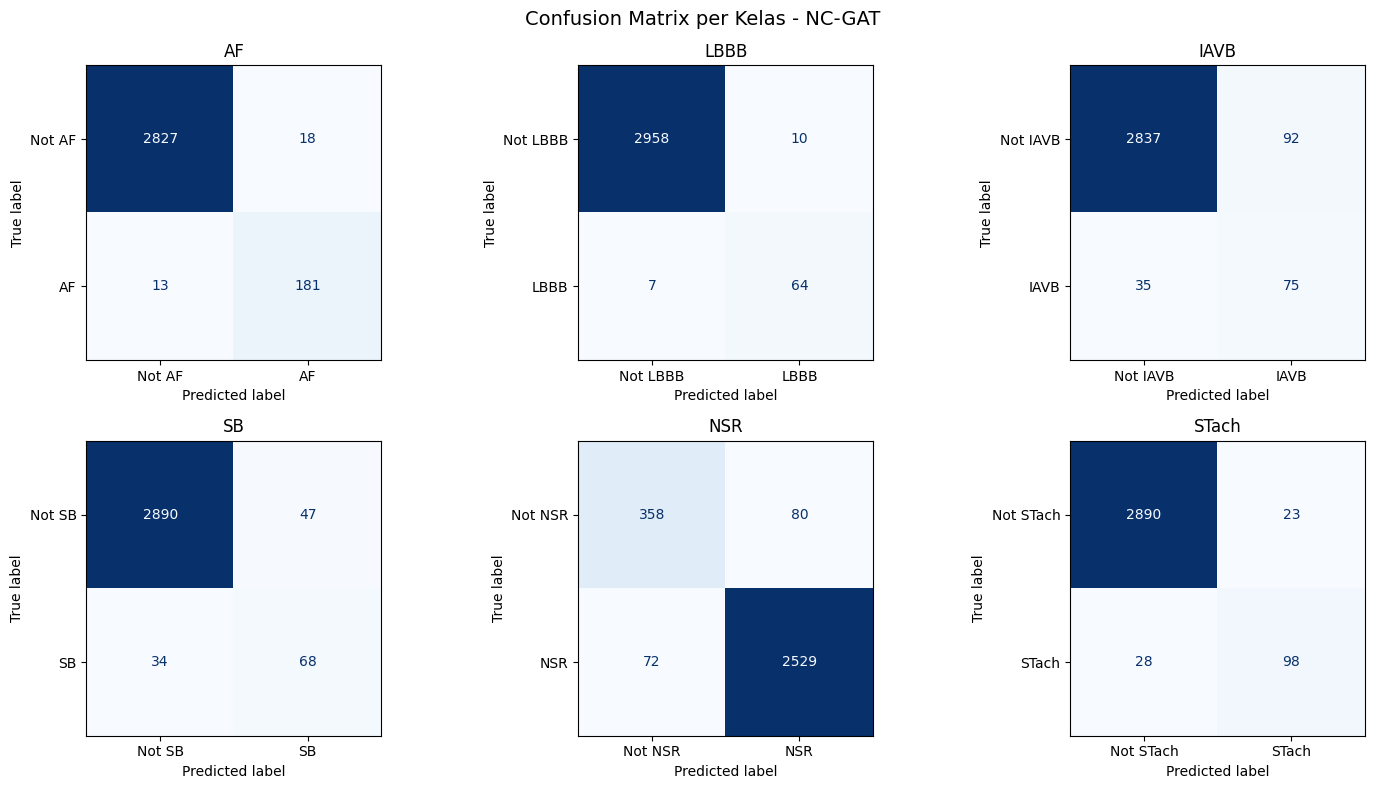

In [25]:
def plot_multilabel_confusion(y_true, y_prob, thresholds, model_name):
    y_pred = (y_prob >= thresholds.reshape(1, -1)).astype(int)
    mcm = multilabel_confusion_matrix(y_true, y_pred)
    fig, axes = plt.subplots(2, 3, figsize=(15, 8)); axes = axes.ravel()
    for i, (cm, code_val) in enumerate(zip(mcm, CLASS_CODES)):
        name = CLASS_NAMES[code_val]
        disp = ConfusionMatrixDisplay(cm, display_labels=[f"Not {name}", name])
        disp.plot(ax=axes[i], colorbar=False, cmap="Blues")
        axes[i].set_title(f"{name}")
    plt.suptitle(f"Confusion Matrix per Kelas - {model_name}", fontsize=14)
    plt.tight_layout()
    plt.savefig(os.path.join(RESULTS_DIR, f"cm_{model_name.replace(' ', '_')}.png"), dpi=120)
    plt.show()


for name in trained_models.keys():
    _, yt, pt = evaluate_model(trained_models[name], test_internal_loader, DEVICE)
    plot_multilabel_confusion(yt, pt, thresholds_per_model[name], name)


### ROC Curve

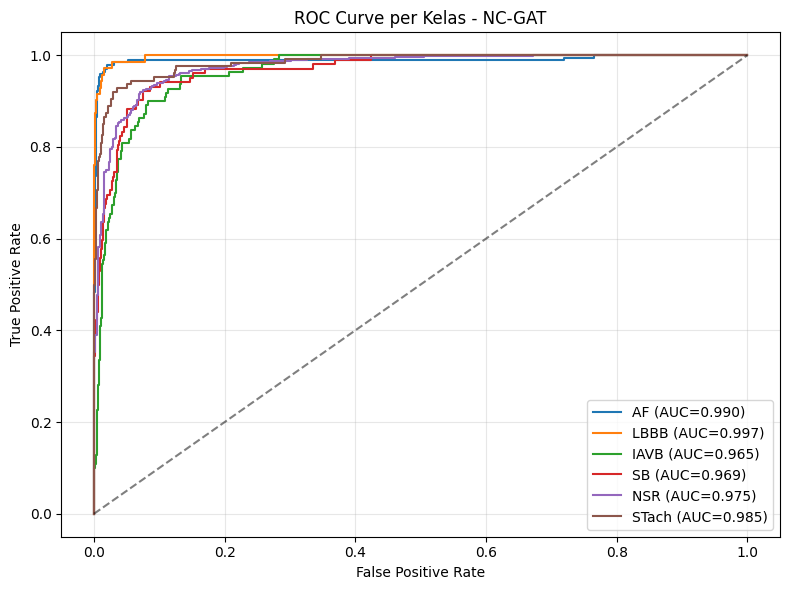

In [26]:
def plot_roc_per_class(y_true, y_prob, model_name):
    fig, ax = plt.subplots(figsize=(8, 6))
    for i, code_val in enumerate(CLASS_CODES):
        fpr, tpr, _ = roc_curve(y_true[:, i], y_prob[:, i])
        auc_val = roc_auc_score(y_true[:, i], y_prob[:, i])
        ax.plot(fpr, tpr, label=f"{CLASS_NAMES[code_val]} (AUC={auc_val:.3f})")
    ax.plot([0, 1], [0, 1], "k--", alpha=0.5)
    ax.set_xlabel("False Positive Rate"); ax.set_ylabel("True Positive Rate")
    ax.set_title(f"ROC Curve per Kelas - {model_name}")
    ax.legend(loc="lower right"); ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(os.path.join(RESULTS_DIR, f"roc_{model_name.replace(' ', '_')}.png"), dpi=120)
    plt.show()


_, yt_nc, pt_nc = evaluate_model(model_gat_nc, test_internal_loader, DEVICE)
plot_roc_per_class(yt_nc, pt_nc, "NC-GAT")


### Training Curve

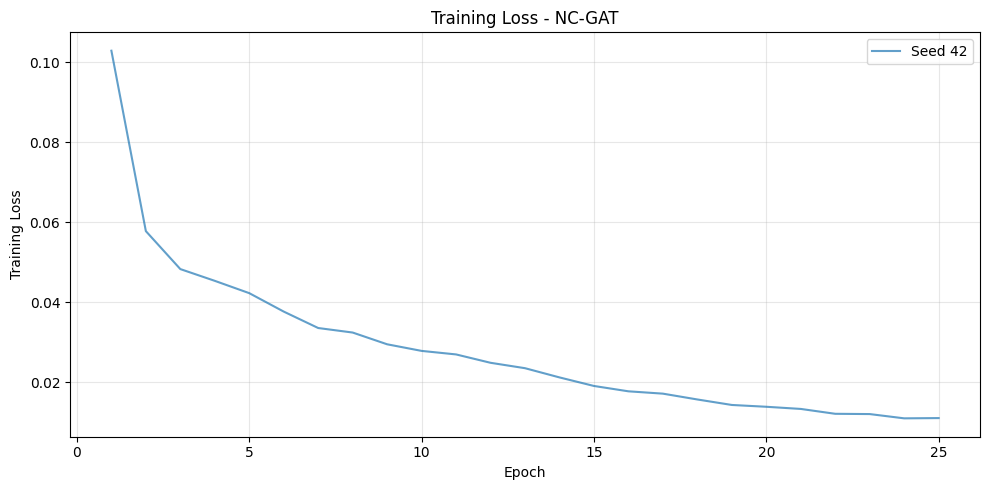

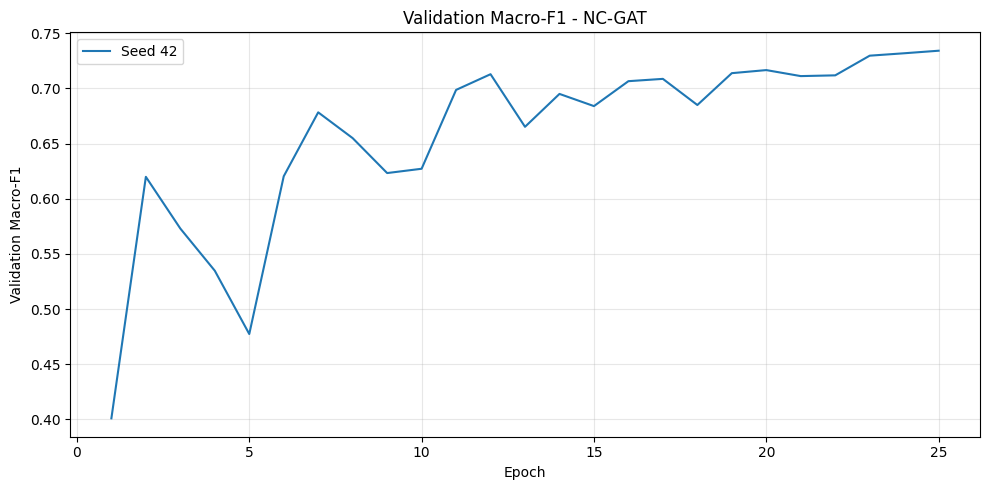

In [27]:
def plot_training_curves(histories, model_name):
    fig, ax = plt.subplots(figsize=(10, 5))
    for i, hist in enumerate(histories):
        ax.plot(range(1, len(hist["loss"]) + 1), hist["loss"], alpha=0.7, label=f"Seed {SEED}")
    ax.set_xlabel("Epoch"); ax.set_ylabel("Training Loss")
    ax.set_title(f"Training Loss - {model_name}")
    ax.legend(); ax.grid(alpha=0.3); plt.tight_layout()
    plt.savefig(os.path.join(RESULTS_DIR, f"curve_loss_{model_name.replace(' ', '_')}.png"), dpi=120)
    plt.show()

    fig, ax = plt.subplots(figsize=(10, 5))
    for i, hist in enumerate(histories):
        ax.plot(range(1, len(hist["val_f1"]) + 1), hist["val_f1"], label=f"Seed {SEED}")
    ax.set_xlabel("Epoch"); ax.set_ylabel("Validation Macro-F1")
    ax.set_title(f"Validation Macro-F1 - {model_name}")
    ax.legend(); ax.grid(alpha=0.3); plt.tight_layout()
    plt.savefig(os.path.join(RESULTS_DIR, f"curve_valf1_{model_name.replace(' ', '_')}.png"), dpi=120)
    plt.show()


plot_training_curves(histories_nc, "NC-GAT")


### Classification Report per Kelas

In [29]:
print("=== Classification Report - NC-GAT (Test Internal PTB-XL) ===")

# Threshold probabilitas jadi label binary dulu
y_pred_nc = (pt_nc >= thresholds_gat_nc.reshape(1, -1)).astype(int)

print(classification_report(yt_nc, y_pred_nc, target_names=CLASS_NAMES_ORDERED,
                             zero_division=0, digits=4))

=== Classification Report - NC-GAT (Test Internal PTB-XL) ===
              precision    recall  f1-score   support

          AF     0.9095    0.9330    0.9211       194
        LBBB     0.8649    0.9014    0.8828        71
        IAVB     0.4491    0.6818    0.5415       110
          SB     0.5913    0.6667    0.6267       102
         NSR     0.9693    0.9723    0.9708      2601
       STach     0.8099    0.7778    0.7935       126

   micro avg     0.9178    0.9410    0.9293      3204
   macro avg     0.7657    0.8222    0.7894      3204
weighted avg     0.9272    0.9410    0.9332      3204
 samples avg     0.9283    0.9476    0.9329      3204



### Eksperimen B - Robustness

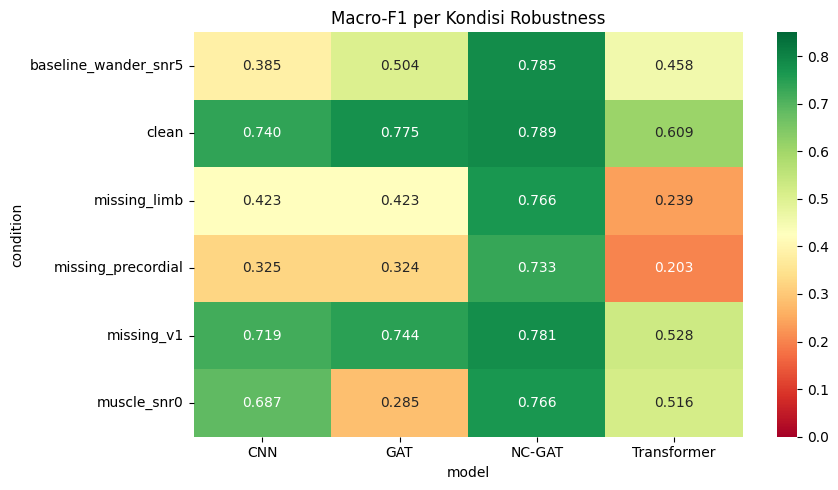

In [30]:
ROBUSTNESS_CONDITIONS = [
    ("clean", "full", "clean", None),
    ("baseline_wander_snr5", "full", "baseline_wander", 5.0),
    ("muscle_snr0", "full", "muscle", 0.0),
    ("missing_v1", "missing_v1", "no_noise", None),
    ("missing_limb", "missing_limb", "no_noise", None),
    ("missing_precordial", "missing_precordial", "no_noise", None),
]


def evaluate_under_condition(model, signals, labels, device, noise_type,
                              missing_scenario, snr_db, threshold):
    aug = (missing_scenario != "full") or (noise_type not in ("clean", "no_noise"))
    ds = ECGDataset(signals, labels, augment=aug,
                    snr_db=snr_db if snr_db else 5.0,
                    noise_type=noise_type, missing_lead_scenario=missing_scenario)
    loader = build_dataloader(ds)
    _, yt, pt = evaluate_model(model, loader, device)
    return compute_metrics(yt, pt, threshold=threshold)


results_b = []
for name, model in trained_models.items():
    th = thresholds_per_model[name]
    for cname, ms, nt, snr in ROBUSTNESS_CONDITIONS:
        m = evaluate_under_condition(model, signals_test, labels_test, DEVICE, nt, ms, snr, th)
        results_b.append({"model": name, "condition": cname, **m})
df_results_b = pd.DataFrame(results_b)

pivot = df_results_b.pivot(index="condition", columns="model", values="macro_f1")
plt.figure(figsize=(9, 5))
sns.heatmap(pivot, annot=True, fmt=".3f", cmap="RdYlGn", vmin=0, vmax=0.85)
plt.title("Macro-F1 per Kondisi Robustness")
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "eksperimen_b_robustness.png"), dpi=120)
plt.show()


### Eksperimen C - Efek Noise-Consistency

              condition  f1_without_nc  f1_with_nc   delta
0                 clean         0.7746      0.7894  0.0148
1  baseline_wander_snr5         0.5094      0.7834  0.2740
2           muscle_snr0         0.2935      0.7658  0.4724
3            missing_v1         0.7443      0.7810  0.0367
4          missing_limb         0.4228      0.7658  0.3429
5    missing_precordial         0.3236      0.7332  0.4096


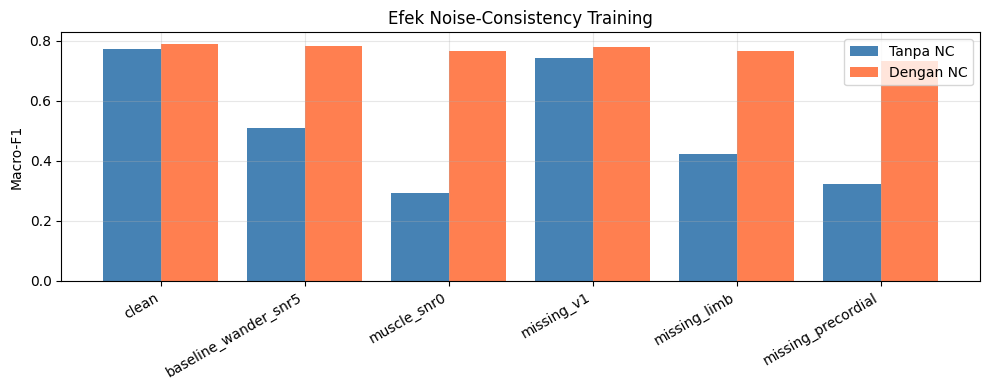

In [31]:
results_c = []
for cname, ms, nt, snr in ROBUSTNESS_CONDITIONS:
    m_no = evaluate_under_condition(trained_models["GAT"], signals_test, labels_test, DEVICE,
                                     nt, ms, snr, thresholds_per_model["GAT"])
    m_nc = evaluate_under_condition(trained_models["NC-GAT"], signals_test, labels_test, DEVICE,
                                     nt, ms, snr, thresholds_per_model["NC-GAT"])
    results_c.append({"condition": cname,
                       "f1_without_nc": m_no["macro_f1"],
                       "f1_with_nc": m_nc["macro_f1"],
                       "delta": m_nc["macro_f1"] - m_no["macro_f1"]})
df_results_c = pd.DataFrame(results_c)
print(df_results_c.round(4))

plt.figure(figsize=(10, 4))
x = np.arange(len(df_results_c))
plt.bar(x - 0.2, df_results_c["f1_without_nc"], 0.4, label="Tanpa NC", color="steelblue")
plt.bar(x + 0.2, df_results_c["f1_with_nc"], 0.4, label="Dengan NC", color="coral")
plt.xticks(x, df_results_c["condition"], rotation=30, ha="right")
plt.ylabel("Macro-F1"); plt.title("Efek Noise-Consistency Training")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "eksperimen_c_nc.png"), dpi=120)
plt.show()


### Eksperimen D - Cross-Dataset

=== Cross-Dataset (PTB-XL ke Chapman) ===
         model  f1_source  f1_target  delta_f1  auroc_source  auroc_target  \
0          CNN     0.7398     0.5918    0.1480        0.9682        0.9071   
1  Transformer     0.6091     0.5063    0.1028        0.9062        0.8421   
2          GAT     0.7746     0.5992    0.1754        0.9779        0.9292   
3       NC-GAT     0.7894     0.6307    0.1587        0.9802        0.9366   

   auprc_source  auprc_target  
0        0.7794        0.7636  
1        0.6262        0.6058  
2        0.8162        0.8178  
3        0.8291        0.8289  


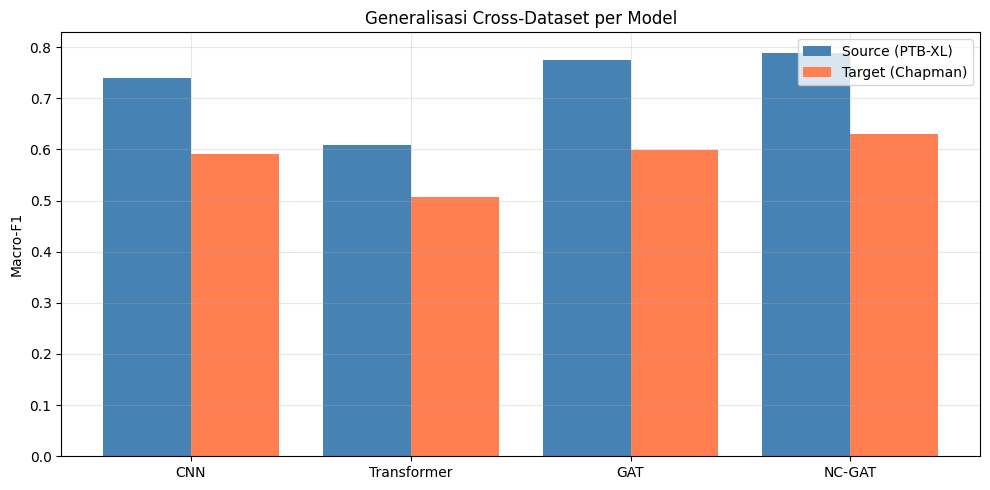

In [32]:
cross_dataset_results = []
for name, model in trained_models.items():
    th = thresholds_per_model[name]
    _, ys, ps = evaluate_model(model, test_internal_loader, DEVICE)
    _, yt, pt = evaluate_model(model, test_external_loader, DEVICE)
    ms = compute_metrics(ys, ps, th)
    mt = compute_metrics(yt, pt, th)
    cross_dataset_results.append({
        "model": name,
        "f1_source": ms["macro_f1"], "f1_target": mt["macro_f1"],
        "delta_f1": ms["macro_f1"] - mt["macro_f1"],
        "auroc_source": ms["auroc_macro"], "auroc_target": mt["auroc_macro"],
        "auprc_source": ms["auprc_macro"], "auprc_target": mt["auprc_macro"],
    })
df_results_d = pd.DataFrame(cross_dataset_results)
print("=== Cross-Dataset (PTB-XL ke Chapman) ===")
print(df_results_d.round(4))

plt.figure(figsize=(10, 5))
x = np.arange(len(df_results_d))
plt.bar(x - 0.2, df_results_d["f1_source"], 0.4, label="Source (PTB-XL)", color="steelblue")
plt.bar(x + 0.2, df_results_d["f1_target"], 0.4, label="Target (Chapman)", color="coral")
plt.xticks(x, df_results_d["model"])
plt.ylabel("Macro-F1"); plt.title("Generalisasi Cross-Dataset per Model")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "eksperimen_d_cross.png"), dpi=120)
plt.show()


### Classification Report di Chapman

In [34]:
_, y_tgt_eval, p_tgt_eval = evaluate_model(model_gat_nc, test_external_loader, DEVICE)
print("=== Classification Report - NC-GAT di Chapman-Shaoxing ===")

# Threshold dulu jadi binary pakai threshold dari validasi PTB-XL
y_pred_tgt = (p_tgt_eval >= thresholds_gat_nc.reshape(1, -1)).astype(int)

print(classification_report(y_tgt_eval, y_pred_tgt, target_names=CLASS_NAMES_ORDERED,
                             zero_division=0, digits=4))

=== Classification Report - NC-GAT di Chapman-Shaoxing ===
              precision    recall  f1-score   support

          AF     0.9605    0.9691    0.9648      1780
        LBBB     0.9419    0.3951    0.5567       205
        IAVB     0.7214    0.5870    0.6473       247
          SB     1.0000    0.1219    0.2173      3889
         NSR     0.3207    0.9786    0.4831      1826
       STach     0.9839    0.8552    0.9150      1568

   micro avg     0.5850    0.5836    0.5843      9515
   macro avg     0.8214    0.6512    0.6307      9515
weighted avg     0.8511    0.5836    0.5416      9515
 samples avg     0.5789    0.5896    0.5803      9515



### Eksperimen E - XAI Stability

In [35]:
def compute_lead_importance_ig(model, x, device, n_steps=32):
    model.eval()
    x = x.to(device)
    baseline = torch.zeros_like(x).to(device)
    diff = x - baseline
    alphas = torch.linspace(0, 1, n_steps, device=device).view(-1, 1, 1, 1)
    interpolated = baseline + alphas * diff.unsqueeze(0)
    grads = []
    for i in range(n_steps):
        xi = interpolated[i].clone().requires_grad_(True)
        out = model(xi).sum()
        g = torch.autograd.grad(out, xi)[0]
        grads.append(g)
    avg_grad = torch.stack(grads).mean(dim=0)
    ig = avg_grad * diff
    imp = ig.abs().sum(dim=-1).cpu().numpy()
    return imp / (imp.sum(axis=-1, keepdims=True) + 1e-12)


def stability_metrics(a, b, top_k=3):
    sp, _ = spearmanr(a, b)
    cs = cosine_similarity(a.reshape(1, -1), b.reshape(1, -1))[0, 0]
    ov = len(set(np.argsort(a)[-top_k:]) & set(np.argsort(b)[-top_k:])) / top_k
    p, q = a + 1e-12, b + 1e-12
    p, q = p / p.sum(), q / q.sum()
    return {"spearman": sp, "cosine": cs, "top_k_overlap": ov,
            "js_divergence": jensenshannon(p, q) ** 2}


sample_x = torch.from_numpy(signals_test[:32])
noisy = sample_x.clone().numpy()
for i in range(noisy.shape[0]):
    noisy[i] = augment_ecg(noisy[i], snr_db=5.0, noise_type="baseline_wander")
noisy = torch.from_numpy(noisy)
sample_ch = torch.from_numpy(signals_chapman[:32])


def evaluate_xai_stability(model, model_name):
    imp_clean = compute_lead_importance_ig(model, sample_x, DEVICE)
    imp_noisy = compute_lead_importance_ig(model, noisy, DEVICE)
    imp_tgt = compute_lead_importance_ig(model, sample_ch, DEVICE)
    stab_noise = pd.DataFrame([stability_metrics(imp_clean[i], imp_noisy[i]) for i in range(32)])
    stab_domain = pd.DataFrame([stability_metrics(imp_clean[i], imp_tgt[i]) for i in range(32)])
    print(f"\n=== {model_name} ===")
    print("Clean vs Noisy:"); print(stab_noise.mean().round(4))
    print("Source vs Target:"); print(stab_domain.mean().round(4))
    return stab_noise.mean().to_dict(), stab_domain.mean().to_dict()


stab_noise_gat, stab_domain_gat = evaluate_xai_stability(trained_models["GAT"], "GAT")
stab_noise_nc, stab_domain_nc = evaluate_xai_stability(model_gat_nc, "NC-GAT")

df_xai_compare = pd.DataFrame([
    {"model": "GAT",
     "noise_spearman": stab_noise_gat["spearman"], "noise_top3": stab_noise_gat["top_k_overlap"],
     "domain_spearman": stab_domain_gat["spearman"], "domain_top3": stab_domain_gat["top_k_overlap"]},
    {"model": "NC-GAT",
     "noise_spearman": stab_noise_nc["spearman"], "noise_top3": stab_noise_nc["top_k_overlap"],
     "domain_spearman": stab_domain_nc["spearman"], "domain_top3": stab_domain_nc["top_k_overlap"]},
])
print("\n=== Perbandingan Kestabilan XAI ===")
print(df_xai_compare.round(4))



=== GAT ===
Clean vs Noisy:
spearman         0.7448
cosine           0.9739
top_k_overlap    0.7083
js_divergence    0.0065
dtype: float64
Source vs Target:
spearman         0.4583
cosine           0.9171
top_k_overlap    0.5625
js_divergence    0.0205
dtype: float64

=== NC-GAT ===
Clean vs Noisy:
spearman         0.8136
cosine           0.9863
top_k_overlap    0.7812
js_divergence    0.0041
dtype: float64
Source vs Target:
spearman         0.0896
cosine           0.8602
top_k_overlap    0.3021
js_divergence    0.0368
dtype: float64

=== Perbandingan Kestabilan XAI ===
    model  noise_spearman  noise_top3  domain_spearman  domain_top3
0     GAT          0.7448      0.7083           0.4583       0.5625
1  NC-GAT          0.8136      0.7812           0.0896       0.3021


### Attention Heatmap antar-Lead

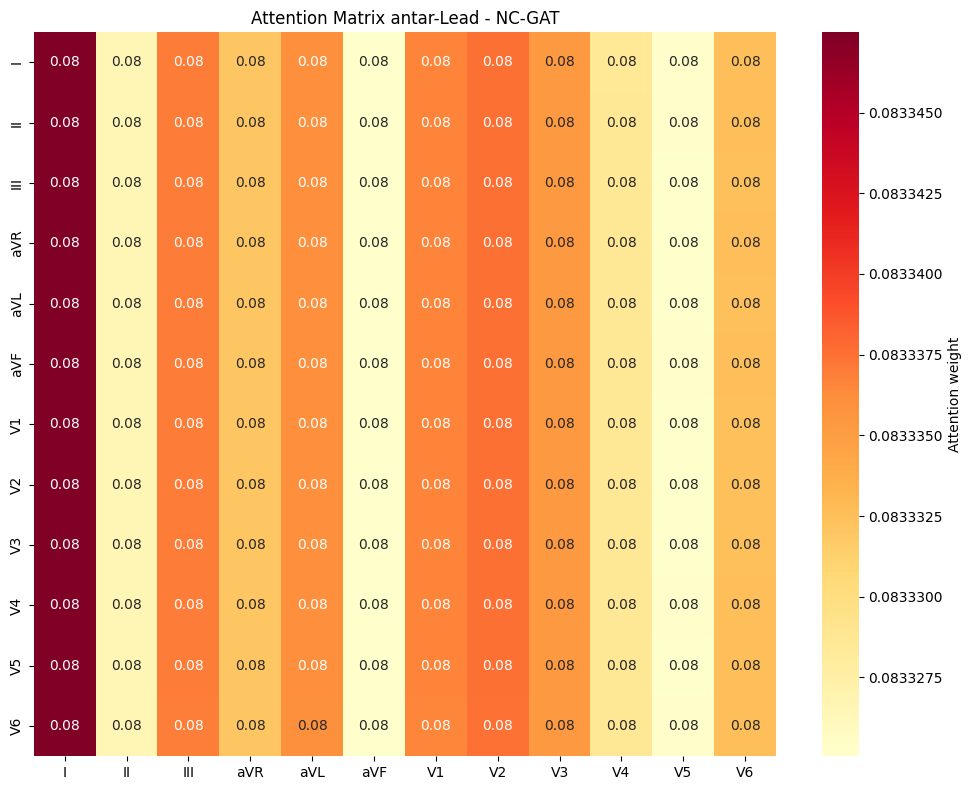

In [36]:
model_gat_nc.eval()
with torch.no_grad():
    _, attn = model_gat_nc(sample_x[:1].to(DEVICE), return_attention=True)
attn_mean = attn.mean(dim=0).mean(dim=0).cpu().numpy()

plt.figure(figsize=(10, 8))
sns.heatmap(attn_mean, xticklabels=LEAD_NAMES, yticklabels=LEAD_NAMES,
            cmap="YlOrRd", annot=True, fmt=".2f",
            cbar_kws={"label": "Attention weight"})
plt.title("Attention Matrix antar-Lead - NC-GAT")
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "attention_heatmap.png"), dpi=120)
plt.show()


### Contoh Output Akhir

In [37]:
@torch.no_grad()
def predict_ecg(model, signal, thresholds, device=DEVICE):
    model.eval()
    x = torch.from_numpy(signal).unsqueeze(0).to(device)
    probs = torch.sigmoid(model(x)).cpu().numpy()[0]
    return {CLASS_NAMES[c]: {
        "probability": round(float(probs[CLASS_CODES.index(c)]), 4),
        "threshold": round(float(thresholds[CLASS_CODES.index(c)]), 2),
        "detected": bool(probs[CLASS_CODES.index(c)] >= thresholds[CLASS_CODES.index(c)]),
    } for c in CLASS_CODES}


def print_prediction(signal, gt_codes, model, thresholds, title):
    print(f"\n--- {title} ---")
    print(f"Ground truth: {[CLASS_NAMES[c] for c in gt_codes]}")
    result = predict_ecg(model, signal, thresholds)
    detected = [k for k, v in result.items() if v["detected"]]
    print(f"Prediksi terdeteksi: {detected}")
    for k, v in result.items():
        status = "DETECTED" if v["detected"] else "not"
        print(f"  {k:6s}: prob={v['probability']:.4f}  (threshold={v['threshold']})  {status}")


for target_code, label in [(426783006, "NSR"), (164889003, "AF"), (164909002, "LBBB")]:
    idx = np.where(labels_test[:, CLASS_CODES.index(target_code)] > 0)[0]
    if len(idx) > 0:
        i = idx[0]
        gt = df_ptbxl_test.iloc[i]["snomed_codes"]
        print_prediction(signals_test[i], gt, model_gat_nc, thresholds_gat_nc,
                         f"Rekaman dengan label {label}")



--- Rekaman dengan label NSR ---
Ground truth: ['NSR']
Prediksi terdeteksi: ['NSR']
  AF    : prob=0.0007  (threshold=0.6)  not
  LBBB  : prob=0.0003  (threshold=0.8)  not
  IAVB  : prob=0.0000  (threshold=0.7)  not
  SB    : prob=0.0014  (threshold=0.7)  not
  NSR   : prob=0.6726  (threshold=0.1)  DETECTED
  STach : prob=0.0004  (threshold=0.9)  not

--- Rekaman dengan label AF ---
Ground truth: ['AF']
Prediksi terdeteksi: ['AF']
  AF    : prob=0.6153  (threshold=0.6)  DETECTED
  LBBB  : prob=0.0000  (threshold=0.8)  not
  IAVB  : prob=0.0008  (threshold=0.7)  not
  SB    : prob=0.0000  (threshold=0.7)  not
  NSR   : prob=0.0005  (threshold=0.1)  not
  STach : prob=0.1660  (threshold=0.9)  not

--- Rekaman dengan label LBBB ---
Ground truth: ['LBBB', 'NSR']
Prediksi terdeteksi: ['LBBB', 'NSR']
  AF    : prob=0.0000  (threshold=0.6)  not
  LBBB  : prob=0.9897  (threshold=0.8)  DETECTED
  IAVB  : prob=0.0000  (threshold=0.7)  not
  SB    : prob=0.0000  (threshold=0.7)  not
  NSR   : pr

### Output per Pasien

In [38]:
@torch.no_grad()
def predict_patient(model, df, signals, patient_id, thresholds, device=DEVICE):
    model.eval()
    mask = df["patient_id"] == patient_id
    idxs = np.where(mask.values)[0]
    results = []
    for i in idxs:
        x = torch.from_numpy(signals[i]).unsqueeze(0).to(device)
        probs = torch.sigmoid(model(x)).cpu().numpy()[0]
        detected = [CLASS_NAMES[c] for c in CLASS_CODES
                    if probs[CLASS_CODES.index(c)] >= thresholds[CLASS_CODES.index(c)]]
        results.append({
            "record": os.path.basename(df.iloc[i]["record_path"]),
            "ground_truth": [CLASS_NAMES[c] for c in df.iloc[i]["snomed_codes"]],
            "predicted": detected,
        })
    return results


patient_counts = df_ptbxl_test.groupby("patient_id").size()
multi_rec = patient_counts[patient_counts > 1].index.tolist()

if multi_rec:
    sample_pid = multi_rec[0]
    pr = predict_patient(model_gat_nc, df_ptbxl_test, signals_test, sample_pid, thresholds_gat_nc)
    print(f"Pasien ID: {sample_pid}")
    print(f"Jumlah rekaman di test: {len(pr)}\n")
    for r in pr:
        print(f"  Record: {r['record']}")
        print(f"    Ground truth : {r['ground_truth']}")
        print(f"    Predicted    : {r['predicted']}")
        print()


Pasien ID: 302.0
Jumlah rekaman di test: 2

  Record: 02510_hr
    Ground truth : ['NSR']
    Predicted    : ['NSR']

  Record: 02513_hr
    Ground truth : ['NSR']
    Predicted    : ['NSR']



---
# TAHAP 10: KESIMPULAN

## Ringkasan Pipeline

| Tahap | Status |
|---|---|
| Dataset | PTB-XL + Chapman-Shaoxing, harmonisasi SNOMED-CT |
| EDA | Distribusi kelas, contoh sinyal, cek kualitas data |
| Preprocessing | Resample 500 Hz, bandpass 0.5-45 Hz, normalisasi per lead, pad 10 detik |
| Clean Dataset | Filter label, harmonisasi, split per pasien (0 overlap) |
| Feature Engineering | N/A - end-to-end deep learning |
| Model Development | CNN 1D, Transformer, GAT, NC-GAT |
| Model Evaluation | Accuracy, Precision, Recall, F1, AUROC, AUPRC, confusion matrix, ROC, robustness, cross-dataset, XAI stability, bootstrap CI, McNemar test |

## Kontribusi

1. Model Graph Attention antar-lead dengan Noise-Consistency Regularization untuk klasifikasi multi-label ECG 12-lead.
2. Evaluasi robustness sistematis terhadap noise dan missing-lead, dibandingkan CNN, Transformer, dan GAT tanpa noise-consistency.
3. Evaluasi generalisasi lintas dataset untuk semua model.
4. Analisis kuantitatif kestabilan XAI dengan Integrated Gradients dan empat metrik kestabilan.
5. **Evaluasi validitas statistik dengan bootstrap 95% CI dan McNemar test**, tanpa memerlukan multi-seed training yang mahal.


In [39]:
import platform
summary = {
    "seed": SEED,
    "reproducibility": {
        "python": platform.python_version(),
        "torch": torch.__version__,
        "numpy": np.__version__,
        "device": str(DEVICE),
    },
    "config": {
        "batch_size": BATCH_SIZE, "lr": LR, "epochs": EPOCHS,
        "patience": PATIENCE, "dropout": DROPOUT,
        "weight_decay": WEIGHT_DECAY, "warmup_epochs": WARMUP_EPOCHS,
    },
    "eksperimen_a": {k: v["mean"] for k, v in agg_results_a.items()},
    "bootstrap_ci_macro_f1": boot_results,
    "mcnemar_gat_vs_ncgat": {"chi2": chi2_stat, "p_value": p_value},
    "eksperimen_b_robustness": df_results_b.to_dict(orient="records"),
    "eksperimen_c_noise_consistency": df_results_c.to_dict(orient="records"),
    "eksperimen_d_cross_dataset": df_results_d.to_dict(orient="records"),
    "eksperimen_e_xai": df_xai_compare.to_dict(orient="records"),
}
with open(os.path.join(RESULTS_DIR, "ncgat_final_summary.json"), "w") as f:
    json.dump(summary, f, indent=2, default=str)

df_results_a.to_csv(os.path.join(RESULTS_DIR, "eksperimen_a_baseline.csv"))
df_results_b.to_csv(os.path.join(RESULTS_DIR, "eksperimen_b_robustness.csv"), index=False)
df_results_c.to_csv(os.path.join(RESULTS_DIR, "eksperimen_c_noise_consistency.csv"), index=False)
df_results_d.to_csv(os.path.join(RESULTS_DIR, "eksperimen_d_cross_dataset.csv"), index=False)
df_xai_compare.to_csv(os.path.join(RESULTS_DIR, "eksperimen_e_xai.csv"), index=False)

print("Semua hasil disimpan di:", RESULTS_DIR)
print("Checkpoint model di:", CHECKPOINT_DIR)


Semua hasil disimpan di: /kaggle/working/nc_gat_final/results
Checkpoint model di: /kaggle/working/nc_gat_final/checkpoints
